# Лабораторная работа №16: Визуальные токенизаторы и autoregressive image generation

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Обучить compact VQ-VAE.
- Измерить reconstruction и codebook utilization.
- Обучить autoregressive prior и сравнить sampling.

## Теоретическая часть

VQ-VAE кодирует изображение в grid latent vectors, заменяет каждый ближайшим codebook vector и декодирует. Индексы становятся visual tokens для autoregressive prior. Малый codebook ухудшает reconstruction, большой может иметь dead codes.

![VQ-VAE](https://raw.githubusercontent.com/CompVis/taming-transformers/master/assets/teaser.png)


VQ-VAE заменяет пространственные признаки ближайшими векторами кодбука, straight-through переносит градиент через дискретизацию. Conditional autoregressive prior предсказывает очередной visual token по уже известным индексам и метке класса.

Для индекса $k^*=\arg\min_k\|z_e-e_k\|_2^2$ straight-through задаёт $z_q=z_e+\operatorname{sg}(e_{k^*}-z_e)$. Perplexity кодов равна $\exp(-\sum_k p_k\log p_k)$.

# Теория

## 1. VQ-VAE — векторно-квантованный вариационный автоэнкодер

**VQ-VAE (Vector Quantized Variational Autoencoder)** — это нейронная сеть, которая сжимает изображение в последовательность дискретных кодов, а затем восстанавливает его обратно.

В отличие от обычного автоэнкодера, который обычно передаёт непрерывные значения, VQ-VAE использует ограниченный набор векторов — кодовую книгу (*codebook*).

Архитектура состоит из трёх основных частей:

1. **Энкодер (Encoder)** — получает исходное изображение и преобразует его в компактное представление.
2. **Кодовая книга (Codebook)** — заменяет полученные векторы ближайшими векторами из заранее заданного набора.
3. **Декодер (Decoder)** — восстанавливает изображение по выбранным векторам.

В работе исходное изображение MNIST размером 28×28 преобразуется в сетку 7×7. Таким образом, вместо 784 пикселей мы получаем 49 визуальных токенов.

### 2. Codebook — кодовая книга

**Codebook** — это набор обучаемых векторов, которые используются для представления визуальной информации.

Каждый элемент кодовой книги можно рассматривать как один из возможных способов представить небольшой фрагмент изображения.

Увеличение размера кодовой книги позволяет хранить больше вариантов визуальных признаков. Однако слишком большой словарь не всегда гарантирует лучшее качество: часть кодов может практически не использоваться.

### 3. Dead codes — неиспользуемые коды

**Dead codes** — это элементы кодовой книги, которые не выбираются при кодировании изображений или используются крайне редко.

### 4. Perplexity — перплексия кодовой книги

Перплексия показывает, насколько равномерно модель использует элементы кодовой книги.

Сначала рассчитывается вероятность использования каждого кода:

$$
p_i = \frac{n_i}{N}
$$

где:
- \(n_i\) — количество использований кода;
- \(N\) — общее количество использований всех кодов.

Затем вычисляется энтропия распределения:

$$
H = -\sum_{i=1}^{K}p_i\ln(p_i)
$$

Перплексия определяется как:

$$
Perplexity = e^H
$$

Если модель использует все коды примерно одинаково, перплексия будет высокой. Если чаще всего выбирается небольшое количество кодов, она будет низкой.

### 5. Обучение VQ-VAE

При обучении VQ-VAE модель должна научиться одновременно хорошо сжимать изображения и восстанавливать их.

Для этого используется функция потерь, состоящая из трёх частей:

$$
L = L_{reconstruction} + L_{codebook} + \beta L_{commitment}
$$

**Ошибка восстановления** показывает, насколько восстановленное изображение отличается от исходного:

$$
L_{reconstruction} = \|x-\hat{x}\|_2^2
$$

**Ошибка кодовой книги** помогает обучать векторы кодовой книги приближаться к выходам энкодера.

**Ошибка обязательства (commitment loss)** заставляет энкодер формировать представления, которые не слишком сильно отличаются от выбранных векторов кодовой книги.

Таким образом, VQ-VAE учится создавать компактное представление изображения, сохраняя важные визуальные особенности.

---

## 6. Авторегрессионный Transformer

После обучения VQ-VAE каждое изображение можно представить последовательностью из 49 визуальных токенов.

Следующий этап — научить другую нейронную сеть генерировать такие последовательности. Для этого используется **авторегрессионный Transformer**.

Авторегрессионная модель генерирует последовательность по одному токену за раз. Каждый следующий токен зависит от уже сгенерированных предыдущих токенов.

### 7. Causal Mask — причинная маска

Для авторегрессионной генерации важно, чтобы модель не могла заглядывать в будущие токены.

Для этого используется **causal mask** — специальная маска внимания, которая запрещает учитывать информацию из будущих позиций.

---

## 8. Генерация токенов: Temperature, Top-k и Top-p

После обучения Transformer можно генерировать новые последовательности токенов.

Однако модель может выдавать несколько возможных вариантов следующего токена. Для управления выбором используются специальные методы.

**Temperature (температура)** регулирует случайность генерации:

$$
P_i = softmax\left(\frac{z_i}{T}\right)
$$

где \(z_i\) — исходный логит, а \(T\) — температура.

- Низкая температура делает распределение более концентрированным: модель чаще выбирает наиболее вероятные токены.
- Высокая температура делает распределение более равномерным и увеличивает случайность.

**Top-k** оставляет только \(k\) наиболее вероятных токенов, а остальные исключает из выбора.

**Top-p** оставляет минимальный набор наиболее вероятных токенов, суммарная вероятность которых достигает заданного порога \(p\).

Эти методы позволяют управлять разнообразием генерируемых изображений и сравнивать разные стратегии генерации.

---

## 9. Энтропия токенов

Энтропия показывает, насколько разнообразно используются визуальные токены при генерации изображений.

Она рассчитывается по формуле:

$$
H=-\sum_{i=1}^{K}p_i\ln(p_i)
$$

где \(p_i\) — доля использования определённого токена среди всех сгенерированных токенов.

### Экспериментальный протокол

MNIST train 20 000/test 2 000; 28×28→7×7 visual tokens. Два токенизатора K=16/64; обученный conditional Transformer; 1000 шагов каждого в полном режиме. Smoke 2 шага — только техническая проверка.

### Материалы

- [VQ-VAE](https://arxiv.org/abs/1711.00937)
- [Taming Transformers](https://github.com/CompVis/taming-transformers)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
SEED = 93
PROJECT_DIR = Path('/content/drive/MyDrive/lab16')
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', PROJECT_DIR / 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', PROJECT_DIR / 'data'))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2))
print({'device':DEVICE,'fast_dev_run':FAST_DEV_RUN,'artifacts':str(ARTIFACTS)})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': '/content/drive/MyDrive/lab16/artifacts'}


In [3]:
# Библиотеки

import torchvision
from torchvision import datasets
import torch.nn as nn
import torch.nn.functional as F
import copy

import pandas as pd
from IPython.display import display
from torch.utils.data import DataLoader, TensorDataset
import math
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

### Архитектура дискретного токенизатора

*Вес: 1 балл.*

**Постановка.** Кодбук должен обучаться на реальных изображениях; random inputs не измеряют качество реконструкции. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите VQ-VAE, ближайший код, straight-through и loss с корректными масштабами.

**Результат.** Проверяемое состояние «Архитектура дискретного токенизатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите VQ-VAE, ближайший код, straight-through и loss с корректными масштабами» и его результат доступен следующему этапу.

In [4]:
# ============================================================
# Загрузка и подготовка MNIST
# ============================================================
BATCH_SIZE = 128
N_TRAIN = 20_000
N_TEST = 2_000

# Загружаем MNIST
train_dataset = datasets.MNIST(
    root=str(DATA_ROOT),
    train=True,
    download=True
)

test_dataset = datasets.MNIST(
    root=str(DATA_ROOT),
    train=False,
    download=True
)

# Детерминированный выбор подмножеств
split_file = ARTIFACTS / "mnist_split.npz"

if split_file.exists():
    saved = np.load(split_file)
    train_indices = saved["train_indices"]
    test_indices = saved["test_indices"]
    print("Загружены ранее сохранённые индексы MNIST.")
else:
    rng = np.random.default_rng(SEED)

    train_indices = rng.permutation(len(train_dataset))[:N_TRAIN]
    test_indices = rng.permutation(len(test_dataset))[:N_TEST]

    np.savez(
        split_file,
        train_indices=train_indices,
        test_indices=test_indices
    )
    print("Индексы MNIST сохранены.")

assert len(train_indices) == N_TRAIN
assert len(test_indices) == N_TEST

# Изображения преобразуем в float32 и диапазон [0, 1]
X_train = (
    train_dataset.data[train_indices]
    .unsqueeze(1)
    .float() / 255.0
)

y_train = train_dataset.targets[train_indices].long()

X_test = (
    test_dataset.data[test_indices]
    .unsqueeze(1)
    .float() / 255.0
)

y_test = test_dataset.targets[test_indices].long()

# Проверяем размеры
assert X_train.shape == (20_000, 1, 28, 28)
assert X_test.shape == (2_000, 1, 28, 28)

# Сохраняем информацию о датасете
dataset_info = {
    "dataset": "MNIST",
    "source": "torchvision.datasets.MNIST",
    "train_samples": len(X_train),
    "test_samples": len(X_test),
    "image_shape": [1, 28, 28],
    "num_classes": 10,
    "normalization": "[0, 1]",
    "seed": SEED,
    "license": "Creative Commons Attribution-Share Alike 3.0 (CC BY-SA 3.0)",
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "fast_dev_run": FAST_DEV_RUN
}

save_json("dataset_info.json", dataset_info)

# Сохраняем подготовленные данные для последующих запусков
data_file = DATA_ROOT / "mnist_prepared.pt"

if not data_file.exists():
    torch.save(
        {
            "X_train": X_train,
            "y_train": y_train,
            "X_test": X_test,
            "y_test": y_test
        },
        data_file
    )

print("Подготовка данных завершена.")
print({
    "train_shape": tuple(X_train.shape),
    "test_shape": tuple(X_test.shape),
    "train_classes": torch.unique(y_train).tolist(),
    "test_classes": torch.unique(y_test).tolist(),
    "device": DEVICE,
    "artifacts": str(ARTIFACTS)
})


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.18MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 182kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.30MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.9MB/s]


Индексы MNIST сохранены.
Подготовка данных завершена.
{'train_shape': (20000, 1, 28, 28), 'test_shape': (2000, 1, 28, 28), 'train_classes': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], 'test_classes': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], 'device': 'cuda', 'artifacts': '/content/drive/MyDrive/lab16/artifacts'}


### Обучение и диагностика двух кодбуков

*Вес: 1 балл.*

**Постановка.** Кодбук должен обучаться на реальных изображениях; random inputs не измеряют качество реконструкции. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите K=16/64 при равном бюджете; измерьте test MSE, used/dead/perplexity и сохраните checkpoint.

**Результат.** Проверяемое состояние «Обучение и диагностика двух кодбуков» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите K=16/64 при равном бюджете; измерьте test MSE, used/dead/perplexity и сохраните checkpoint» и его результат доступен следующему этапу.

In [5]:
# ============================================================
# VQ-VAE: обучение K=16 и K=64
# ============================================================
data_file = DATA_ROOT / "mnist_prepared.pt"

assert data_file.exists(), "Сначала выполните задание 1."

try:
    prepared = torch.load(
        data_file, map_location="cpu", weights_only=False
    )
except TypeError:
    prepared = torch.load(data_file, map_location="cpu")

X_train = prepared["X_train"]
y_train = prepared["y_train"]
X_test = prepared["X_test"]
y_test = prepared["y_test"]

X_train = X_train.contiguous()
X_test = X_test.contiguous()

# Параметры эксперимента
LATENT_DIM = 64
BATCH_SIZE = 128
LEARNING_RATE = 2e-3
BETA = 0.25

TRAIN_STEPS = 2 if FAST_DEV_RUN else 1000
SAVE_EVERY = 10

# ------------------------------------------------------------
# 1. Архитектура VQ-VAE
# ------------------------------------------------------------
class VectorQuantizer(nn.Module):
    def __init__(self, num_embeddings, embedding_dim, beta=0.25):
        super().__init__()

        self.num_embeddings = num_embeddings
        self.embedding_dim = embedding_dim
        self.beta = beta

        self.embedding = nn.Embedding(
            num_embeddings, embedding_dim
        )

        nn.init.uniform_(
            self.embedding.weight,
            -1.0 / num_embeddings,
            1.0 / num_embeddings
        )

    def forward(self, z):
        # z: [B, C, 7, 7]
        B, C, H, W = z.shape

        # Переставляем каналы в конец
        z_perm = z.permute(0, 2, 3, 1).contiguous()

        flat_z = z_perm.view(-1, C)

        # Вычисляем расстояние до всех векторов Codebook
        distances = (
            flat_z.pow(2).sum(dim=1, keepdim=True)
            + self.embedding.weight.pow(2).sum(dim=1)
            - 2 * flat_z @ self.embedding.weight.t()
        )

        # Выбираем ближайший вектор
        indices = distances.argmin(dim=1)

        quantized = self.embedding(indices)
        quantized = quantized.view(B, H, W, C)

        # Loss Codebook
        codebook_loss = F.mse_loss(
            quantized, z_perm.detach()
        )

        # Commitment loss
        commitment_loss = F.mse_loss(
            z_perm, quantized.detach()
        )

        vq_loss = codebook_loss + self.beta * commitment_loss

        # Straight-through estimator
        quantized_st = z_perm + (quantized - z_perm).detach()

        quantized_st = quantized_st.permute(
            0, 3, 1, 2
        ).contiguous()

        return (
            quantized_st,
            vq_loss,
            indices.view(B, H, W)
        )

class VQVAE(nn.Module):
    def __init__(self, num_embeddings, latent_dim=64):
        super().__init__()

        # 28x28 -> 14x14 -> 7x7
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, latent_dim, 4, stride=2, padding=1)
        )
        self.quantizer = VectorQuantizer(
            num_embeddings, latent_dim, BETA
        )
        # 7x7 -> 14x14 -> 28x28
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(
                latent_dim, 32, 4, stride=2, padding=1
            ),
            nn.ReLU(),
            nn.ConvTranspose2d(
                32, 1, 4, stride=2, padding=1
            ),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)

        z_q, vq_loss, indices = self.quantizer(z)

        reconstruction = self.decoder(z_q)

        return reconstruction, vq_loss, indices

    @torch.no_grad()
    def encode_indices(self, x):
        z = self.encoder(x)

        _, _, indices = self.quantizer(z)

        return indices


# ------------------------------------------------------------
# 2. Функции сохранения checkpoint
# ------------------------------------------------------------

def atomic_torch_save(obj, path):
    path = Path(path)
    temp_path = path.with_suffix(path.suffix + ".tmp")

    torch.save(obj, temp_path)
    os.replace(temp_path, path)


def save_checkpoint(
    path, model, optimizer, step, generator, history, K
):
    checkpoint = {
        "K": K,
        "step": step,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "generator_state": generator.get_state(),
        "history": history,
        "seed": SEED,
        "latent_dim": LATENT_DIM,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "beta": BETA,
        "fast_dev_run": FAST_DEV_RUN
    }

    atomic_torch_save(checkpoint, path)


# ------------------------------------------------------------
# 3. Обучение одного VQ-VAE
# ------------------------------------------------------------

def train_vqvae(K):

    checkpoint_path = ARTIFACTS / f"vqvae_k{K}_last.pt"
    metrics_path = ARTIFACTS / f"vqvae_k{K}_metrics.json"

    # Отдельный seed для каждого Codebook
    torch.manual_seed(SEED + K)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED + K)

    model = VQVAE(K, LATENT_DIM).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    generator = torch.Generator(device="cpu")
    generator.manual_seed(SEED + K + 1000)

    history = []
    start_step = 0

    # Восстановление состояния после прерывания
    if checkpoint_path.exists():
        try:
            try:
                checkpoint = torch.load(
                    checkpoint_path,
                    map_location=DEVICE,
                    weights_only=False
                )
            except TypeError:
                checkpoint = torch.load(
                    checkpoint_path,
                    map_location=DEVICE
                )

            if checkpoint["K"] != K:
                raise ValueError("Несовпадение K в checkpoint.")

            if checkpoint["latent_dim"] != LATENT_DIM:
                raise ValueError("Несовпадение LATENT_DIM.")

            model.load_state_dict(checkpoint["model"])
            optimizer.load_state_dict(checkpoint["optimizer"])

            generator.set_state(checkpoint["generator_state"])

            start_step = checkpoint["step"]
            history = checkpoint["history"]

            print(
                f"K={K}: восстановлено состояние с шага {start_step}"
            )

        except Exception as e:
            raise RuntimeError(
                f"Не удалось восстановить checkpoint K={K}: {e}"
            )

    else:
        print(f"K={K}: начинаем обучение с нуля.")

    # Если обучение уже завершено, не обучаем повторно
    if start_step >= TRAIN_STEPS:
        print(f"K={K}: нужный бюджет уже выполнен.")

    model.train()
    start_time = time.time()

    try:
        for step in range(start_step, TRAIN_STEPS):

            # Случайный batch реальных изображений MNIST
            batch_indices = torch.randint(
                0,
                len(X_train),
                (BATCH_SIZE,),
                generator=generator
            )

            x = X_train[batch_indices].to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            reconstruction, vq_loss, indices = model(x)

            reconstruction_loss = F.mse_loss(
                reconstruction, x
            )

            loss = reconstruction_loss + vq_loss

            loss.backward()

            optimizer.step()

            current_step = step + 1

            record = {
                "step": current_step,
                "loss": float(loss.detach().cpu()),
                "reconstruction_loss": float(
                    reconstruction_loss.detach().cpu()
                ),
                "vq_loss": float(vq_loss.detach().cpu())
            }

            history.append(record)

            # Сохранение каждые SAVE_EVERY шагов
            if (
                current_step % SAVE_EVERY == 0
                or current_step == TRAIN_STEPS
            ):
                save_checkpoint(
                    checkpoint_path,
                    model,
                    optimizer,
                    current_step,
                    generator,
                    history,
                    K
                )

                print(
                    f"K={K} | шаг {current_step}/{TRAIN_STEPS} | "
                    f"loss={record['loss']:.5f} | "
                    f"reconstruction={record['reconstruction_loss']:.5f}"
                )

    except KeyboardInterrupt:
        # При ручном прерывании сохраняем текущее состояние
        save_checkpoint(
            checkpoint_path,
            model,
            optimizer,
            current_step if 'current_step' in locals() else start_step,
            generator,
            history,
            K
        )

        print(
            f"K={K}: обучение прервано. "
            "Состояние сохранено, можно продолжить запуском ячейки."
        )
        raise

    # --------------------------------------------------------
    # 4. Оценка на тестовой выборке
    # --------------------------------------------------------

    model.eval()

    squared_error = 0.0
    total_pixels = 0
    all_indices = []

    with torch.no_grad():
        for begin in range(0, len(X_test), BATCH_SIZE):

            x = X_test[begin:begin + BATCH_SIZE].to(DEVICE)

            reconstruction, _, indices = model(x)

            squared_error += F.mse_loss(
                reconstruction, x, reduction="sum"
            ).item()

            total_pixels += x.numel()

            all_indices.append(indices.cpu().reshape(-1))

    test_mse = squared_error / total_pixels

    all_indices = torch.cat(all_indices)

    # Использование Codebook
    code_counts = torch.bincount(
        all_indices,
        minlength=K
    ).float()

    probabilities = code_counts / code_counts.sum()

    used_codes = int((code_counts > 0).sum().item())
    dead_codes = K - used_codes

    nonzero_probs = probabilities[probabilities > 0]

    perplexity = torch.exp(
        -(nonzero_probs * torch.log(nonzero_probs)).sum()
    ).item()

    utilization = used_codes / K

    metrics = {
        "K": K,
        "train_steps_completed": TRAIN_STEPS,
        "test_mse": test_mse,
        "used_codes": used_codes,
        "dead_codes": dead_codes,
        "codebook_utilization": utilization,
        "perplexity": perplexity,
        "total_codes": K,
        "training_time_seconds": time.time() - start_time,
        "fast_dev_run": FAST_DEV_RUN,
        "seed": SEED
    }

    # Сохраняем метрики
    save_json(
        f"vqvae_k{K}_metrics.json",
        metrics
    )

    # Сохраняем финальный checkpoint
    save_checkpoint(
        checkpoint_path,
        model,
        optimizer,
        TRAIN_STEPS,
        generator,
        history,
        K
    )

    print(f"\nРезультаты K={K}:")
    print(json.dumps(metrics, indent=2, ensure_ascii=False))

    return metrics


# ------------------------------------------------------------
# 5. Запуск двух экспериментов
# ------------------------------------------------------------

all_metrics = {}

for K in [16, 64]:
    print("\n" + "=" * 55)
    print(f"ОБУЧЕНИЕ VQ-VAE С K={K}")
    print("=" * 55)

    all_metrics[f"K={K}"] = train_vqvae(K)

# Общий файл с результатами
save_json("vqvae_comparison.json", all_metrics)

print("\nСРАВНЕНИЕ ДВУХ CODEBOOK")
print(json.dumps(all_metrics, indent=2, ensure_ascii=False))

print("\nВсе эксперименты завершены.")
print("Артефакты:", ARTIFACTS)



ОБУЧЕНИЕ VQ-VAE С K=16
K=16: начинаем обучение с нуля.
K=16 | шаг 10/1000 | loss=0.49648 | reconstruction=0.15048
K=16 | шаг 20/1000 | loss=0.87501 | reconstruction=0.09845
K=16 | шаг 30/1000 | loss=1.76910 | reconstruction=0.06537
K=16 | шаг 40/1000 | loss=1.08472 | reconstruction=0.05419
K=16 | шаг 50/1000 | loss=0.59766 | reconstruction=0.04622
K=16 | шаг 60/1000 | loss=0.30676 | reconstruction=0.03998
K=16 | шаг 70/1000 | loss=0.18557 | reconstruction=0.03692
K=16 | шаг 80/1000 | loss=0.11841 | reconstruction=0.03234
K=16 | шаг 90/1000 | loss=0.09854 | reconstruction=0.02919
K=16 | шаг 100/1000 | loss=0.09164 | reconstruction=0.02773
K=16 | шаг 110/1000 | loss=0.08267 | reconstruction=0.02471
K=16 | шаг 120/1000 | loss=0.09081 | reconstruction=0.02452
K=16 | шаг 130/1000 | loss=0.09901 | reconstruction=0.02381
K=16 | шаг 140/1000 | loss=0.10996 | reconstruction=0.02339
K=16 | шаг 150/1000 | loss=0.11915 | reconstruction=0.02190
K=16 | шаг 160/1000 | loss=0.12976 | reconstruction=0

In [6]:
results = []

for K in [16, 64]:
    path = ARTIFACTS / f"vqvae_k{K}_metrics.json"

    with open(path, "r", encoding="utf-8") as f:
        metrics = json.load(f)

    results.append({
        "Codebook K": K,
        "Test MSE": metrics["test_mse"],
        "Used codes": metrics["used_codes"],
        "Dead codes": metrics["dead_codes"],
        "Perplexity": metrics["perplexity"],
        "Utilization (%)": metrics["codebook_utilization"] * 100,
        "Training steps": metrics["train_steps_completed"]
    })

df_results = pd.DataFrame(results)

print("Сравнение двух обученных VQ-VAE:")
display(
    df_results.style.format({
        "Test MSE": "{:.6f}",
        "Perplexity": "{:.3f}",
        "Utilization (%)": "{:.2f}%"
    })
)


Сравнение двух обученных VQ-VAE:


,Codebook K,Test MSE,Used codes,Dead codes,Perplexity,Utilization (%),Training steps
0,16,0.008526,16,0,7.284,100.00%,1000
1,64,0.005445,64,0,16.766,100.00%,1000


### Индексы обученного токенизатора

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Закодируйте train/test только обученной VQ-VAE K=64.

**Результат.** Проверяемое состояние «Индексы обученного токенизатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Закодируйте train/test только обученной VQ-VAE K=64» и его результат доступен следующему этапу.

In [7]:
# ============================================================
# Индексы обученного токенизатора K=64
# ============================================================
K = 64
BATCH_SIZE = 256

checkpoint_path = ARTIFACTS / "vqvae_k64_last.pt"

assert checkpoint_path.exists(), (
    "Не найден checkpoint VQ-VAE K=64. "
    "Сначала обучите токенизатор."
)

# Загружаем checkpoint
try:
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE
    )

assert checkpoint["K"] == K

# Создаём модель и загружаем обученные веса
tokenizer = VQVAE(
    num_embeddings=K,
    latent_dim=checkpoint["latent_dim"]
).to(DEVICE)

tokenizer.load_state_dict(checkpoint["model"])
tokenizer.eval()

# ------------------------------------------------------------
# Кодирование изображений в индексы Codebook
# ------------------------------------------------------------

@torch.no_grad()
def encode_dataset(images, batch_size=256):

    all_indices = []

    for start in range(0, len(images), batch_size):

        batch = images[start:start + batch_size].to(DEVICE)

        # Получаем индексы ближайших векторов Codebook
        indices = tokenizer.encode_indices(batch)

        all_indices.append(indices.cpu())

    return torch.cat(all_indices, dim=0)


print("Кодирование train...")
train_tokens = encode_dataset(X_train, BATCH_SIZE)

print("Кодирование test...")
test_tokens = encode_dataset(X_test, BATCH_SIZE)

# ------------------------------------------------------------
# Проверки корректности
# ------------------------------------------------------------

assert train_tokens.shape == (20_000, 7, 7)
assert test_tokens.shape == (2_000, 7, 7)

assert train_tokens.min() >= 0
assert train_tokens.max() < K

assert test_tokens.min() >= 0
assert test_tokens.max() < K

# Метки классов сохраняем вместе с токенами
token_data = {
    "train_tokens": train_tokens.long(),
    "train_labels": y_train.long(),
    "test_tokens": test_tokens.long(),
    "test_labels": y_test.long(),
    "codebook_size": K,
    "grid_size": [7, 7],
    "tokenizer": "VQ-VAE K=64",
    "tokenizer_checkpoint": str(checkpoint_path),
    "seed": SEED
}

# Атомарное сохранение: при прерывании не оставляем
# частично записанный файл под основным именем
token_file = ARTIFACTS / "mnist_tokens_k64.pt"
temp_file = ARTIFACTS / "mnist_tokens_k64.tmp"

torch.save(token_data, temp_file)
temp_file.replace(token_file)

# ------------------------------------------------------------
# Диагностика полученных токенов
# ------------------------------------------------------------

all_tokens = torch.cat([
    train_tokens.reshape(-1),
    test_tokens.reshape(-1)
])

counts = torch.bincount(all_tokens, minlength=K)

used_codes = int((counts > 0).sum())
dead_codes = K - used_codes

probs = counts.float() / counts.sum()
probs = probs[probs > 0]

perplexity = torch.exp(
    -(probs * torch.log(probs)).sum()
).item()

token_info = {
    "train_images": len(train_tokens),
    "test_images": len(test_tokens),
    "tokens_per_image": 49,
    "train_tokens_total": train_tokens.numel(),
    "test_tokens_total": test_tokens.numel(),
    "codebook_size": K,
    "used_codes": used_codes,
    "dead_codes": dead_codes,
    "perplexity": perplexity,
    "token_shape_train": list(train_tokens.shape),
    "token_shape_test": list(test_tokens.shape),
    "token_min": int(all_tokens.min()),
    "token_max": int(all_tokens.max()),
    "tokenizer_checkpoint": str(checkpoint_path)
}

save_json("mnist_tokens_k64_info.json", token_info)

print("\nКодирование завершено!")
print(json.dumps(token_info, indent=2, ensure_ascii=False))
print("\nФайл токенов:", token_file)


Кодирование train...
Кодирование test...

Кодирование завершено!
{
  "train_images": 20000,
  "test_images": 2000,
  "tokens_per_image": 49,
  "train_tokens_total": 980000,
  "test_tokens_total": 98000,
  "codebook_size": 64,
  "used_codes": 64,
  "dead_codes": 0,
  "perplexity": 16.760665893554688,
  "token_shape_train": [
    20000,
    7,
    7
  ],
  "token_shape_test": [
    2000,
    7,
    7
  ],
  "token_min": 0,
  "token_max": 63,
  "tokenizer_checkpoint": "/content/drive/MyDrive/lab16/artifacts/vqvae_k64_last.pt"
}

Файл токенов: /content/drive/MyDrive/lab16/artifacts/mnist_tokens_k64.pt


### Причинная маска prior

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте Transformer с BOS и маской, исключающей просмотр будущих токенов.

**Результат.** Проверяемое состояние «Причинная маска prior» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте Transformer с BOS и маской, исключающей просмотр будущих токенов» и его результат доступен следующему этапу.

In [8]:
# ============================================================
# Transformer Prior с причинной маской и BOS
# ============================================================

# Проверяем наличие токенизированного датасета
token_file = ARTIFACTS / "mnist_tokens_k64.pt"

assert token_file.exists(), (
    "Сначала выполните задание 'Индексы обученного токенизатора'."
)

# Загружаем токены
try:
    token_data = torch.load(
        token_file,
        map_location="cpu",
        weights_only=False
    )
except TypeError:
    token_data = torch.load(token_file, map_location="cpu")

# Проверяем размеры данных
assert token_data["train_tokens"].shape == (20_000, 7, 7)
assert token_data["test_tokens"].shape == (2_000, 7, 7)

# ------------------------------------------------------------
# 1. Конфигурация Transformer
# ------------------------------------------------------------

VOCAB_SIZE = 64
BOS_TOKEN = 64
NUM_CLASSES = 10
SEQ_LEN = 49

D_MODEL = 128
N_HEADS = 4
NUM_LAYERS = 4
DIM_FEEDFORWARD = 256
DROPOUT = 0.1

# ------------------------------------------------------------
# 2. Архитектура Autoregressive Transformer
# ------------------------------------------------------------

class AutoregressivePrior(nn.Module):

    def __init__(
        self,
        vocab_size=64,
        num_classes=10,
        seq_len=49,
        d_model=128,
        n_heads=4,
        num_layers=4,
        dim_feedforward=256,
        dropout=0.1
    ):
        super().__init__()

        self.vocab_size = vocab_size
        self.bos_token = vocab_size
        self.seq_len = seq_len
        self.d_model = d_model

        # Embedding визуальных токенов + BOS
        self.token_embedding = nn.Embedding(
            vocab_size + 1,
            d_model
        )

        # Embedding метки класса MNIST
        self.class_embedding = nn.Embedding(
            num_classes,
            d_model
        )

        # Позиционные эмбеддинги
        self.position_embedding = nn.Parameter(
            torch.randn(1, seq_len, d_model) * 0.02
        )

        # Transformer Encoder с causal mask
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
            enable_nested_tensor=False
        )

        self.norm = nn.LayerNorm(d_model)

        # Предсказание следующего визуального токена
        self.output_head = nn.Linear(
            d_model,
            vocab_size
        )

    def causal_mask(self, length, device):
        """
        True означает, что позиция запрещена для просмотра.
        Маска блокирует все будущие позиции.
        """
        return torch.triu(
            torch.ones(
                length,
                length,
                dtype=torch.bool,
                device=device
            ),
            diagonal=1
        )

    def forward(self, input_ids, labels):
        """
        input_ids: [B, L], содержит BOS и предыдущие токены.
        labels:    [B], метки классов MNIST.

        Выход: [B, L, vocab_size] — логиты следующих токенов.
        """

        B, L = input_ids.shape

        assert L <= self.seq_len
        assert input_ids.min() >= 0
        assert input_ids.max() <= self.bos_token

        # Векторные представления токенов
        x = self.token_embedding(input_ids)

        # Условие класса добавляется ко всем позициям
        class_emb = self.class_embedding(labels).unsqueeze(1)

        # Добавляем позиционные и классовые эмбеддинги
        x = (
            x
            + self.position_embedding[:, :L, :]
            + class_emb
        )

        # Причинная маска
        mask = self.causal_mask(L, input_ids.device)

        # Transformer не видит будущие токены
        x = self.transformer(
            x,
            mask=mask,
            is_causal=True
        )

        x = self.norm(x)

        # Логиты для предсказания следующих токенов
        logits = self.output_head(x)

        return logits


# ------------------------------------------------------------
# 3. Инициализация модели
# ------------------------------------------------------------

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

prior = AutoregressivePrior(
    vocab_size=VOCAB_SIZE,
    num_classes=NUM_CLASSES,
    seq_len=SEQ_LEN,
    d_model=D_MODEL,
    n_heads=N_HEADS,
    num_layers=NUM_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
).to(DEVICE)

# ------------------------------------------------------------
# 4. Проверка BOS и причинной маски
# ------------------------------------------------------------

# Формируем тестовую последовательность:
# BOS + 48 визуальных токенов
sample_tokens = token_data["train_tokens"][:2].reshape(2, 49)

sample_input = torch.cat(
    [
        torch.full((2, 1), BOS_TOKEN, dtype=torch.long),
        sample_tokens[:, :-1]
    ],
    dim=1
).to(DEVICE)

sample_labels = token_data["train_labels"][:2].to(DEVICE)

prior.eval()

with torch.no_grad():
    sample_logits = prior(sample_input, sample_labels)

assert sample_logits.shape == (2, 49, 64)

# Проверяем размерность causal mask
test_mask = prior.causal_mask(SEQ_LEN, DEVICE)

assert test_mask.shape == (49, 49)
assert not test_mask.diagonal().any()

# Все элементы выше главной диагонали должны быть запрещены
assert test_mask[0, 1:].all()

# Все элементы на диагонали и ниже должны быть разрешены
assert not test_mask.tril().any()

# Проверяем отсутствие утечки будущих токенов:
# Изменение будущих входов не должно менять прошлые логиты.
test_prefix = sample_input[:1, :6].clone()
changed_prefix = test_prefix.clone()

changed_prefix[:, 4:] = (
    changed_prefix[:, 4:] + 1
) % (VOCAB_SIZE + 1)

test_label = sample_labels[:1]

with torch.no_grad():
    logits_original = prior(test_prefix, test_label)
    logits_changed = prior(changed_prefix, test_label)

causal_error = (
    logits_original[:, :4] - logits_changed[:, :4]
).abs().max().item()

assert causal_error < 1e-5, (
    f"Обнаружена утечка будущих токенов: {causal_error}"
)

# ------------------------------------------------------------
# 5. Сохранение конфигурации и checkpoint
# ------------------------------------------------------------

prior_config = {
    "model": "AutoregressivePrior",
    "vocab_size": VOCAB_SIZE,
    "bos_token": BOS_TOKEN,
    "num_classes": NUM_CLASSES,
    "sequence_length": SEQ_LEN,
    "latent_grid": [7, 7],
    "d_model": D_MODEL,
    "n_heads": N_HEADS,
    "num_layers": NUM_LAYERS,
    "dim_feedforward": DIM_FEEDFORWARD,
    "dropout": DROPOUT,
    "activation": "gelu",
    "causal_mask": True,
    "class_conditioning": True,
    "tokenizer": "VQ-VAE K=64",
    "seed": SEED
}

save_json("prior_config.json", prior_config)

prior_checkpoint = {
    "model_state_dict": prior.state_dict(),
    "config": prior_config,
    "training_step": 0,
    "status": "initialized"
}

atomic_torch_save(
    prior_checkpoint,
    ARTIFACTS / "prior_init.pt"
)

# ------------------------------------------------------------
# 6. Вывод результатов проверки
# ------------------------------------------------------------

print("Причинная маска Prior успешно создана!")
print(json.dumps({
    "model_parameters": sum(
        p.numel() for p in prior.parameters()
    ),
    "input_shape": list(sample_input.shape),
    "output_shape": list(sample_logits.shape),
    "causal_mask_shape": list(test_mask.shape),
    "bos_token": BOS_TOKEN,
    "vocab_size": VOCAB_SIZE,
    "causal_leakage_error": causal_error,
    "causal_mask_valid": True,
    "checkpoint": str(ARTIFACTS / "prior_init.pt")
}, indent=2, ensure_ascii=False))


Причинная маска Prior успешно создана!
{
  "model_parameters": 554304,
  "input_shape": [
    2,
    49
  ],
  "output_shape": [
    2,
    49,
    64
  ],
  "causal_mask_shape": [
    49,
    49
  ],
  "bos_token": 64,
  "vocab_size": 64,
  "causal_leakage_error": 0.0,
  "causal_mask_valid": true,
  "checkpoint": "/content/drive/MyDrive/lab16/artifacts/prior_init.pt"
}


### Обучение autoregressive prior

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте CE сдвинутой последовательности с checkpoint.

**Результат.** Проверяемое состояние «Обучение autoregressive prior» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте CE сдвинутой последовательности с checkpoint» и его результат доступен следующему этапу.

In [9]:
# ============================================================
# Обучение autoregressive prior
# ============================================================

# Параметры
PRIOR_TRAIN_STEPS = 2 if FAST_DEV_RUN else 1000
PRIOR_BATCH_SIZE = 128
PRIOR_LR = 3e-4
PRIOR_SAVE_EVERY = 10

TOKENS_PATH = ARTIFACTS / "mnist_tokens_k64.pt"
INIT_PATH = ARTIFACTS / "prior_init.pt"
LAST_PATH = ARTIFACTS / "prior_last.pt"
METRICS_PATH = ARTIFACTS / "prior_metrics.json"

assert TOKENS_PATH.exists()
assert INIT_PATH.exists()

# ------------------------------------------------------------
# 1. Загружаем токены
# ------------------------------------------------------------

token_data = torch.load(
    TOKENS_PATH,
    map_location="cpu",
    weights_only=False
)

train_tokens = token_data["train_tokens"].long().reshape(-1, 49)
train_labels = token_data["train_labels"].long()

assert train_tokens.shape == (20000, 49)
assert train_tokens.min() >= 0
assert train_tokens.max() < 64

print("Train tokens:", train_tokens.shape)
print("Диапазон индексов:", int(train_tokens.min()), "-", int(train_tokens.max()))

# ------------------------------------------------------------
# 2. Создаём модель и оптимизатор
# ------------------------------------------------------------

init_checkpoint = torch.load(
    INIT_PATH,
    map_location="cpu",
    weights_only=False
)

model = AutoregressivePrior().to(DEVICE)
model.load_state_dict(init_checkpoint["model_state_dict"])

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=PRIOR_LR,
    weight_decay=0.01
)

batch_generator = torch.Generator(device="cpu")
batch_generator.manual_seed(SEED)

start_step = 0
history = []

# Восстановление обучения
if LAST_PATH.exists():
    checkpoint = torch.load(
        LAST_PATH,
        map_location="cpu",
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    start_step = checkpoint["step"]
    history = checkpoint.get("history", [])

    if "generator_state" in checkpoint:
        batch_generator.set_state(checkpoint["generator_state"])

    print(f"Возобновляем обучение с шага {start_step}")
else:
    print("Начинаем обучение с prior_init.pt")

# ------------------------------------------------------------
# 3. Подготовка сдвинутой последовательности
# ------------------------------------------------------------

BOS_TOKEN = 64

def make_prior_batch(tokens, labels):
    # BOS создаётся на том же устройстве, что и tokens
    bos = torch.full(
        (tokens.size(0), 1),
        BOS_TOKEN,
        dtype=torch.long,
        device=tokens.device
    )

    # Вход:  [BOS, x1, x2, ..., x48]
    # Цель:  [x1,  x2, x3, ..., x49]
    input_ids = torch.cat(
        [bos, tokens[:, :-1]],
        dim=1
    )

    return input_ids, tokens, labels


# ------------------------------------------------------------
# 4. Сохранение checkpoint
# ------------------------------------------------------------

def save_prior_checkpoint(step):
    checkpoint = {
        "step": step,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "generator_state": batch_generator.get_state(),
        "history": history,
        "config": {
            "vocab_size": 64,
            "bos_token": BOS_TOKEN,
            "num_classes": 10,
            "sequence_length": 49,
            "batch_size": PRIOR_BATCH_SIZE,
            "learning_rate": PRIOR_LR,
            "train_steps_target": PRIOR_TRAIN_STEPS,
            "seed": SEED
        }
    }

    temp_path = LAST_PATH.with_suffix(".tmp")
    torch.save(checkpoint, temp_path)
    temp_path.replace(LAST_PATH)


# ------------------------------------------------------------
# 5. Обучение
# ------------------------------------------------------------

model.train()
training_start = time.time()
current_step = start_step

try:
    for step in range(start_step, PRIOR_TRAIN_STEPS):

        indices = torch.randint(
            0,
            len(train_tokens),
            (PRIOR_BATCH_SIZE,),
            generator=batch_generator
        )

        batch_tokens = train_tokens[indices].to(DEVICE)
        batch_labels = train_labels[indices].to(DEVICE)

        input_ids, targets, labels = make_prior_batch(
            batch_tokens,
            batch_labels
        )

        optimizer.zero_grad(set_to_none=True)

        logits = model(input_ids, labels)

        # CE по 49 позициям
        loss = F.cross_entropy(
            logits.reshape(-1, 64),
            targets.reshape(-1)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        current_step = step + 1

        history.append({
            "step": current_step,
            "train_ce": float(loss.item())
        })

        print(
            f"Step {current_step}/{PRIOR_TRAIN_STEPS} | "
            f"Train CE: {loss.item():.6f}"
        )

        if current_step % PRIOR_SAVE_EVERY == 0:
            save_prior_checkpoint(current_step)

except KeyboardInterrupt:
    print("Обучение прервано. Сохраняем checkpoint.")

finally:
    save_prior_checkpoint(current_step)

training_time = time.time() - training_start

# ------------------------------------------------------------
# 6. Сохраняем результаты обучения
# ------------------------------------------------------------

metrics = {
    "status": (
        "completed"
        if current_step >= PRIOR_TRAIN_STEPS
        else "interrupted"
    ),
    "train_steps_completed": current_step,
    "train_steps_target": PRIOR_TRAIN_STEPS,
    "last_train_ce": history[-1]["train_ce"] if history else None,
    "training_time_seconds": training_time,
    "batch_size": PRIOR_BATCH_SIZE,
    "learning_rate": PRIOR_LR,
    "vocab_size": 64,
    "sequence_length": 49,
    "bos_token": BOS_TOKEN,
    "tokenizer": "VQ-VAE K=64",
    "checkpoint": str(LAST_PATH),
    "seed": SEED,
    "test_evaluation": "not_performed"
}

save_json("prior_metrics.json", metrics)

print("\n" + "=" * 50)
print("ОБУЧЕНИЕ AUTOREGRESSIVE PRIOR")
print("=" * 50)
print("Статус:", metrics["status"])
print("Выполнено шагов:", current_step)
print(f"Последний Train CE: {metrics['last_train_ce']:.6f}"
      if metrics["last_train_ce"] is not None else "Train CE: нет данных")
print(f"Время обучения: {training_time:.1f} сек.")
print("Checkpoint:", LAST_PATH)
print("Метрики:", METRICS_PATH)
print("Оценка на тестовой выборке не выполнялась.")


Train tokens: torch.Size([20000, 49])
Диапазон индексов: 0 - 63
Начинаем обучение с prior_init.pt
Step 1/1000 | Train CE: 4.495946
Step 2/1000 | Train CE: 4.328087
Step 3/1000 | Train CE: 4.148969
Step 4/1000 | Train CE: 3.980460
Step 5/1000 | Train CE: 3.829801
Step 6/1000 | Train CE: 3.685403
Step 7/1000 | Train CE: 3.576318
Step 8/1000 | Train CE: 3.438127
Step 9/1000 | Train CE: 3.335830
Step 10/1000 | Train CE: 3.208866
Step 11/1000 | Train CE: 3.112903
Step 12/1000 | Train CE: 3.098584
Step 13/1000 | Train CE: 2.989162
Step 14/1000 | Train CE: 2.969455
Step 15/1000 | Train CE: 2.911905
Step 16/1000 | Train CE: 2.861307
Step 17/1000 | Train CE: 2.885987
Step 18/1000 | Train CE: 2.844415
Step 19/1000 | Train CE: 2.858328
Step 20/1000 | Train CE: 2.835353
Step 21/1000 | Train CE: 2.824084
Step 22/1000 | Train CE: 2.811056
Step 23/1000 | Train CE: 2.759356
Step 24/1000 | Train CE: 2.791673
Step 25/1000 | Train CE: 2.729569
Step 26/1000 | Train CE: 2.729323
Step 27/1000 | Train CE: 2.

### Cross-entropy на test токенах

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оцените CE независимых test токенов без обновления весов.

**Результат.** Проверяемое состояние «Cross-entropy на test токенах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оцените CE независимых test токенов без обновления весов» и его результат доступен следующему этапу.

In [10]:
# ============================================================
# Оценка Cross-Entropy на test токенах
# ============================================================

TOKENS_PATH = ARTIFACTS / "mnist_tokens_k64.pt"
CHECKPOINT_PATH = ARTIFACTS / "prior_last.pt"
TEST_METRICS_PATH = ARTIFACTS / "prior_test_metrics.json"

assert TOKENS_PATH.exists(), f"Не найден файл: {TOKENS_PATH}"
assert CHECKPOINT_PATH.exists(), f"Не найден checkpoint: {CHECKPOINT_PATH}"

# ------------------------------------------------------------
# 1. Загружаем независимые тестовые токены
# ------------------------------------------------------------

token_data = torch.load(
    TOKENS_PATH,
    map_location="cpu",
    weights_only=False
)

test_tokens = token_data["test_tokens"].long().reshape(-1, 49)
test_labels = token_data["test_labels"].long()

assert test_tokens.shape == (2000, 49)
assert test_tokens.min() >= 0
assert test_tokens.max() < 64

print("Test tokens:", test_tokens.shape)
print("Test labels:", test_labels.shape)

# ------------------------------------------------------------
# 2. Загружаем обученный Transformer
# ------------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model = AutoregressivePrior().to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])

model.eval()

print("Загружен checkpoint, шаг обучения:", checkpoint["step"])

# ------------------------------------------------------------
# 3. Подготовка сдвинутой последовательности
# ------------------------------------------------------------

BOS_TOKEN = 64
BATCH_SIZE_EVAL = 128

def make_test_batch(tokens, labels):
    bos = torch.full(
        (tokens.size(0), 1),
        BOS_TOKEN,
        dtype=torch.long,
        device=tokens.device
    )

    # Input:  [BOS, x1, x2, ..., x48]
    # Target: [x1,  x2, x3, ..., x49]
    input_ids = torch.cat(
        [bos, tokens[:, :-1]],
        dim=1
    )

    return input_ids, tokens, labels


# ------------------------------------------------------------
# 4. Оценка Test Cross-Entropy
# ------------------------------------------------------------

total_loss = 0.0
total_tokens = 0

model.eval()

with torch.no_grad():
    for start in range(0, len(test_tokens), BATCH_SIZE_EVAL):

        end = min(start + BATCH_SIZE_EVAL, len(test_tokens))

        batch_tokens = test_tokens[start:end].to(DEVICE)
        batch_labels = test_labels[start:end].to(DEVICE)

        input_ids, targets, labels = make_test_batch(
            batch_tokens,
            batch_labels
        )

        logits = model(input_ids, labels)

        # Суммарная CE по всем токенам батча
        loss = F.cross_entropy(
            logits.reshape(-1, 64),
            targets.reshape(-1),
            reduction="sum"
        )

        total_loss += loss.item()
        total_tokens += targets.numel()

# Средняя CE на один токен
test_ce = total_loss / total_tokens

# ------------------------------------------------------------
# 5. Сохраняем результаты
# ------------------------------------------------------------

test_metrics = {
    "status": "completed",
    "test_cross_entropy": test_ce,
    "test_samples": len(test_tokens),
    "test_tokens_evaluated": total_tokens,
    "sequence_length": 49,
    "vocab_size": 64,
    "bos_token": BOS_TOKEN,
    "checkpoint_step": checkpoint["step"],
    "checkpoint": str(CHECKPOINT_PATH),
    "tokenizer": "VQ-VAE K=64",
    "weights_updated": False,
    "evaluation_mode": "eval + no_grad"
}

save_json("prior_test_metrics.json", test_metrics)

# ------------------------------------------------------------
# 6. Вывод результатов
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("CROSS-ENTROPY НА TEST ТОКЕНАХ")
print("=" * 55)

print(f"Статус:                  {test_metrics['status']}")
print(f"Test samples:            {len(test_tokens)}")
print(f"Количество test токенов: {total_tokens}")
print(f"Test Cross-Entropy:      {test_ce:.6f}")
print(f"Checkpoint step:         {checkpoint['step']}")
print(f"Веса обновлялись:        {test_metrics['weights_updated']}")
print(f"Результаты сохранены:    {TEST_METRICS_PATH}")


Test tokens: torch.Size([2000, 49])
Test labels: torch.Size([2000])
Загружен checkpoint, шаг обучения: 1000

CROSS-ENTROPY НА TEST ТОКЕНАХ
Статус:                  completed
Test samples:            2000
Количество test токенов: 98000
Test Cross-Entropy:      1.170518
Checkpoint step:         1000
Веса обновлялись:        False
Результаты сохранены:    /content/drive/MyDrive/lab16/artifacts/prior_test_metrics.json


In [11]:
with open(ARTIFACTS / "prior_metrics.json", encoding="utf-8") as f:
    train_metrics = json.load(f)

with open(ARTIFACTS / "prior_test_metrics.json", encoding="utf-8") as f:
    test_metrics = json.load(f)

df_ce = pd.DataFrame([
    {
        "Выборка": "Train",
        "Cross-Entropy": train_metrics["last_train_ce"]
    },
    {
        "Выборка": "Test",
        "Cross-Entropy": test_metrics["test_cross_entropy"]
    }
])

display(df_ce.style.format({"Cross-Entropy": "{:.6f}"}))


,Выборка,Cross-Entropy
0,Train,1.243792
1,Test,1.170518


### Архитектура проверяющего классификатора

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите отдельную сеть для class agreement.

**Результат.** Проверяемое состояние «Архитектура проверяющего классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите отдельную сеть для class agreement» и его результат доступен следующему этапу.

In [12]:
# ============================================================
# Архитектура проверяющего классификатора
# ============================================================

# Параметры классификатора
CLASSIFIER_CONFIG = {
    "input_channels": 1,
    "num_classes": 10,
    "conv1_channels": 32,
    "conv2_channels": 64,
    "hidden_dim": 128,
    "dropout": 0.25,
    "input_size": 28
}


class ClassAgreementCNN(nn.Module):
    """
    Отдельный классификатор MNIST для проверки
    соответствия сгенерированного изображения классу.
    """

    def __init__(self, config=CLASSIFIER_CONFIG):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 28 -> 14

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)   # 14 -> 7
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(config["dropout"]),
            nn.Linear(128, config["num_classes"])
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# Создаём сеть
class_agreement_model = ClassAgreementCNN().to(DEVICE)

# Количество параметров
num_parameters = sum(
    p.numel() for p in class_agreement_model.parameters()
    if p.requires_grad
)

# Сохраняем конфигурацию
save_json("class_agreement_config.json", {
    **CLASSIFIER_CONFIG,
    "architecture": "ClassAgreementCNN",
    "num_parameters": num_parameters,
    "input_shape": [1, 28, 28],
    "output_classes": list(range(10))
})

# Сохраняем начальные веса
init_path = ARTIFACTS / "class_agreement_init.pt"

torch.save({
    "model_state_dict": class_agreement_model.state_dict(),
    "config": CLASSIFIER_CONFIG,
    "num_parameters": num_parameters,
    "status": "initialized"
}, init_path)

# Проверяем форму выхода
with torch.no_grad():
    dummy = torch.randn(2, 1, 28, 28).to(DEVICE)
    output = class_agreement_model(dummy)

assert output.shape == (2, 10)

print("Архитектура ClassAgreementCNN создана")
print("Вход:", (1, 28, 28))
print("Выход:", tuple(output.shape))
print("Обучаемых параметров:", num_parameters)
print("Конфигурация:", ARTIFACTS / "class_agreement_config.json")
print("Начальные веса:", init_path)


Архитектура ClassAgreementCNN создана
Вход: (1, 28, 28)
Выход: (2, 10)
Обучаемых параметров: 421834
Конфигурация: /content/drive/MyDrive/lab16/artifacts/class_agreement_config.json
Начальные веса: /content/drive/MyDrive/lab16/artifacts/class_agreement_init.pt


### Обучение и реальный test классификатора

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите на train и проверьте точность на независимом real test.

**Результат.** Проверяемое состояние «Обучение и реальный test классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите на train и проверьте точность на независимом real test» и его результат доступен следующему этапу.

In [13]:
# ============================================================
# Обучение и проверка class agreement classifier
# ============================================================

# Параметры обучения
CLASSIFIER_STEPS = 2 if FAST_DEV_RUN else 1000
CLASSIFIER_BATCH_SIZE = 128
CLASSIFIER_LR = 1e-3
CLASSIFIER_SAVE_EVERY = 50

DATA_PATH = DATA_ROOT / "mnist_prepared.pt"
INIT_PATH = ARTIFACTS / "class_agreement_init.pt"
LAST_PATH = ARTIFACTS / "class_agreement_last.pt"
METRICS_PATH = ARTIFACTS / "class_agreement_metrics.json"

assert DATA_PATH.exists(), f"Не найден файл данных: {DATA_PATH}"
assert INIT_PATH.exists(), f"Не найдены начальные веса: {INIT_PATH}"

# ------------------------------------------------------------
# 1. Загружаем настоящие изображения MNIST
# ------------------------------------------------------------

mnist_data = torch.load(
    DATA_PATH,
    map_location="cpu",
    weights_only=False
)

X_train = mnist_data["X_train"].float()
y_train = mnist_data["y_train"].long()
X_test = mnist_data["X_test"].float()
y_test = mnist_data["y_test"].long()

assert X_train.shape == (20000, 1, 28, 28)
assert X_test.shape == (2000, 1, 28, 28)

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

# ------------------------------------------------------------
# 2. Создаём модель и оптимизатор
# ------------------------------------------------------------

init_checkpoint = torch.load(
    INIT_PATH,
    map_location="cpu",
    weights_only=False
)

model = ClassAgreementCNN().to(DEVICE)
model.load_state_dict(init_checkpoint["model_state_dict"])

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CLASSIFIER_LR,
    weight_decay=1e-4
)

batch_generator = torch.Generator(device="cpu")
batch_generator.manual_seed(SEED + 1)

start_step = 0
history = []

# Восстановление checkpoint, если он существует
if LAST_PATH.exists():
    checkpoint = torch.load(
        LAST_PATH,
        map_location="cpu",
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    start_step = checkpoint["step"]
    history = checkpoint.get("history", [])

    if "generator_state" in checkpoint:
        batch_generator.set_state(checkpoint["generator_state"])

    print(f"Продолжаем обучение с шага {start_step}")
else:
    print("Начинаем обучение с начальных весов")

# ------------------------------------------------------------
# 3. Функция сохранения checkpoint
# ------------------------------------------------------------

def save_classifier_checkpoint(step):
    state = {
        "step": step,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "generator_state": batch_generator.get_state(),
        "history": history,
        "config": {
            "batch_size": CLASSIFIER_BATCH_SIZE,
            "learning_rate": CLASSIFIER_LR,
            "target_steps": CLASSIFIER_STEPS,
            "seed": SEED
        }
    }

    temp_path = LAST_PATH.with_suffix(".tmp")
    torch.save(state, temp_path)
    temp_path.replace(LAST_PATH)


# ------------------------------------------------------------
# 4. Обучение на train
# ------------------------------------------------------------

model.train()
training_start = time.time()
current_step = start_step

try:
    for step in range(start_step, CLASSIFIER_STEPS):

        indices = torch.randint(
            0,
            len(X_train),
            (CLASSIFIER_BATCH_SIZE,),
            generator=batch_generator
        )

        images = X_train[indices].to(DEVICE)
        labels = y_train[indices].to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)

        loss = F.cross_entropy(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        current_step = step + 1

        predictions = logits.argmax(dim=1)
        train_accuracy = (
            predictions == labels
        ).float().mean().item()

        history.append({
            "step": current_step,
            "train_loss": float(loss.item()),
            "train_accuracy": float(train_accuracy)
        })

        if current_step == 1 or current_step % 10 == 0:
            print(
                f"Step {current_step}/{CLASSIFIER_STEPS} | "
                f"Train CE: {loss.item():.4f} | "
                f"Batch accuracy: {train_accuracy * 100:.2f}%"
            )

        if current_step % CLASSIFIER_SAVE_EVERY == 0:
            save_classifier_checkpoint(current_step)

except KeyboardInterrupt:
    print("Обучение прервано. Сохраняем checkpoint.")

finally:
    save_classifier_checkpoint(current_step)

training_time = time.time() - training_start

# ------------------------------------------------------------
# 5. Оценка на независимом real test
# ------------------------------------------------------------

model.eval()

correct = 0
total = 0
test_loss_sum = 0.0

with torch.no_grad():
    for start in range(0, len(X_test), CLASSIFIER_BATCH_SIZE):

        end = min(start + CLASSIFIER_BATCH_SIZE, len(X_test))

        images = X_test[start:end].to(DEVICE)
        labels = y_test[start:end].to(DEVICE)

        logits = model(images)

        loss = F.cross_entropy(
            logits,
            labels,
            reduction="sum"
        )

        predictions = logits.argmax(dim=1)

        test_loss_sum += loss.item()
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = correct / total
test_ce = test_loss_sum / total

# ------------------------------------------------------------
# 6. Сохраняем метрики
# ------------------------------------------------------------

metrics = {
    "status": (
        "completed"
        if current_step >= CLASSIFIER_STEPS
        else "interrupted"
    ),
    "train_steps_completed": current_step,
    "train_steps_target": CLASSIFIER_STEPS,
    "last_train_ce": history[-1]["train_loss"] if history else None,
    "test_accuracy": test_accuracy,
    "test_accuracy_percent": test_accuracy * 100,
    "test_cross_entropy": test_ce,
    "test_samples": total,
    "training_time_seconds": training_time,
    "batch_size": CLASSIFIER_BATCH_SIZE,
    "learning_rate": CLASSIFIER_LR,
    "architecture": "ClassAgreementCNN",
    "training_data": "Real MNIST train",
    "evaluation_data": "Independent real MNIST test",
    "checkpoint": str(LAST_PATH),
    "seed": SEED
}

save_json("class_agreement_metrics.json", metrics)

print("\n" + "=" * 55)
print("CLASS AGREEMENT CLASSIFIER")
print("=" * 55)
print("Статус:", metrics["status"])
print("Шагов обучения:", current_step)
print(f"Последний Train CE: {metrics['last_train_ce']:.6f}")
print(f"Test CE: {test_ce:.6f}")
print(f"Real Test Accuracy: {test_accuracy * 100:.2f}%")
print("Тестовых изображений:", total)
print(f"Время обучения: {training_time:.1f} сек.")
print("Checkpoint:", LAST_PATH)
print("Метрики:", METRICS_PATH)


Train: torch.Size([20000, 1, 28, 28]) torch.Size([20000])
Test: torch.Size([2000, 1, 28, 28]) torch.Size([2000])
Начинаем обучение с начальных весов
Step 1/1000 | Train CE: 2.3323 | Batch accuracy: 9.38%
Step 10/1000 | Train CE: 0.8675 | Batch accuracy: 71.09%
Step 20/1000 | Train CE: 0.4911 | Batch accuracy: 82.81%
Step 30/1000 | Train CE: 0.3387 | Batch accuracy: 89.84%
Step 40/1000 | Train CE: 0.3408 | Batch accuracy: 93.75%
Step 50/1000 | Train CE: 0.1780 | Batch accuracy: 95.31%
Step 60/1000 | Train CE: 0.1910 | Batch accuracy: 95.31%
Step 70/1000 | Train CE: 0.1580 | Batch accuracy: 95.31%
Step 80/1000 | Train CE: 0.1486 | Batch accuracy: 98.44%
Step 90/1000 | Train CE: 0.0868 | Batch accuracy: 98.44%
Step 100/1000 | Train CE: 0.1123 | Batch accuracy: 96.88%
Step 110/1000 | Train CE: 0.2190 | Batch accuracy: 93.75%
Step 120/1000 | Train CE: 0.0255 | Batch accuracy: 100.00%
Step 130/1000 | Train CE: 0.0868 | Batch accuracy: 98.44%
Step 140/1000 | Train CE: 0.0518 | Batch accuracy:

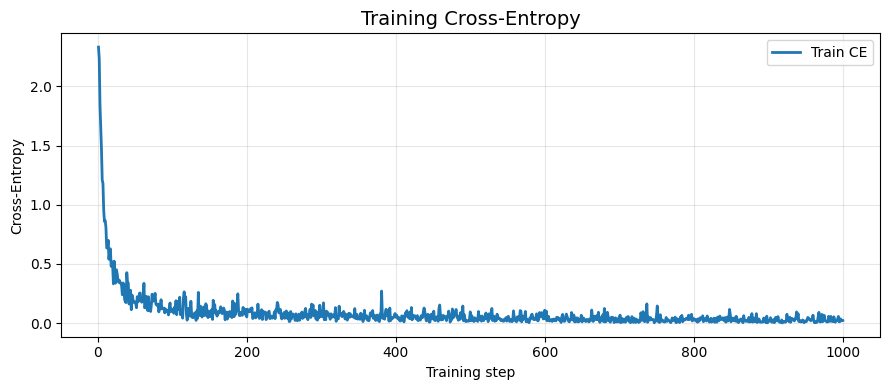

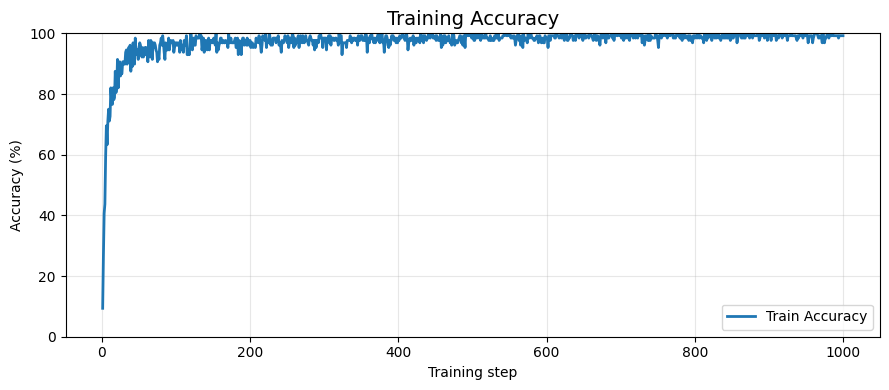

ИТОГОВАЯ ACCURACY


Выборка,Accuracy (%)
Train (последний batch),99.22%
Test (вся выборка),98.30%


Проверенная Test Accuracy: 98.30%


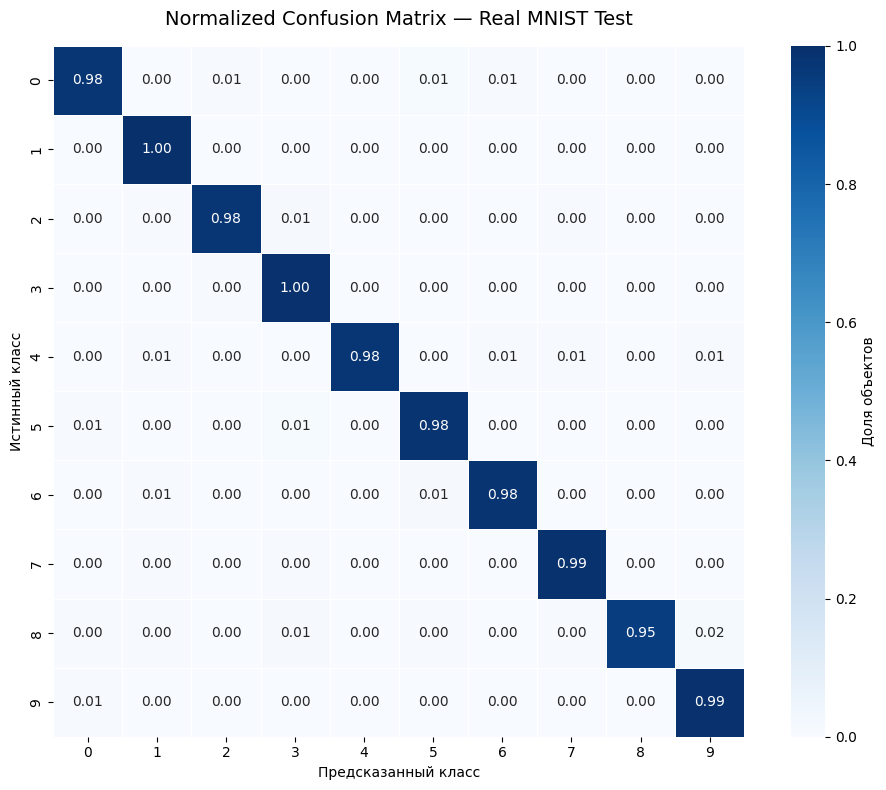

Матрица ошибок сохранена:
/content/drive/MyDrive/lab16/artifacts/class_agreement_confusion_matrix.npy


In [14]:
# ============================================================
# ВИЗУАЛИЗАЦИЯ CLASS AGREEMENT CLASSIFIER
# ============================================================

# ------------------------------------------------------------
# 1. Загружаем историю обучения и итоговые метрики
# ------------------------------------------------------------

metrics_path = ARTIFACTS / "class_agreement_metrics.json"
checkpoint_path = ARTIFACTS / "class_agreement_last.pt"
data_path = DATA_ROOT / "mnist_prepared.pt"

with open(metrics_path, "r", encoding="utf-8") as f:
    metrics = json.load(f)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

history = checkpoint["history"]

steps = [item["step"] for item in history]
train_losses = [item["train_loss"] for item in history]
train_accuracies = [item["train_accuracy"] * 100 for item in history]

# ------------------------------------------------------------
# 2. График Train Cross-Entropy
# ------------------------------------------------------------

plt.figure(figsize=(9, 4))

plt.plot(
    steps,
    train_losses,
    linewidth=2,
    label="Train CE"
)

plt.title("Training Cross-Entropy", fontsize=14)
plt.xlabel("Training step")
plt.ylabel("Cross-Entropy")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. График Train Accuracy
# ------------------------------------------------------------

plt.figure(figsize=(9, 4))

plt.plot(
    steps,
    train_accuracies,
    linewidth=2,
    label="Train Accuracy"
)

plt.title("Training Accuracy", fontsize=14)
plt.xlabel("Training step")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Итоговая Train Accuracy и Test Accuracy
# ------------------------------------------------------------

# Последняя batch accuracy из истории обучения
final_train_accuracy = (
    train_accuracies[-1] if train_accuracies else float("nan")
)

final_test_accuracy = metrics["test_accuracy_percent"]

accuracy_table = pd.DataFrame({
    "Выборка": ["Train (последний batch)", "Test (вся выборка)"],
    "Accuracy (%)": [
        final_train_accuracy,
        final_test_accuracy
    ]
})

print("ИТОГОВАЯ ACCURACY")
display(
    accuracy_table.style.format({
        "Accuracy (%)": "{:.2f}%"
    }).hide(axis="index")
)

# ------------------------------------------------------------
# 5. Загружаем классификатор
# ------------------------------------------------------------

model = ClassAgreementCNN().to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

data = torch.load(
    data_path,
    map_location="cpu",
    weights_only=False
)

X_test = data["X_test"].float()
y_test = data["y_test"].long()

# ------------------------------------------------------------
# 6. Получаем предсказания на test
# ------------------------------------------------------------

all_predictions = []

with torch.no_grad():
    for start in range(0, len(X_test), CLASSIFIER_BATCH_SIZE):
        end = min(start + CLASSIFIER_BATCH_SIZE, len(X_test))

        images = X_test[start:end].to(DEVICE)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())

y_true = y_test.numpy()
y_pred = np.array(all_predictions)

# Проверяем, что предсказания совпадают с сохранённой accuracy
calculated_accuracy = (y_true == y_pred).mean() * 100

print(f"Проверенная Test Accuracy: {calculated_accuracy:.2f}%")

# ------------------------------------------------------------
# 7. Нормированная матрица ошибок
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(10)),
    normalize="true"
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.5,
    xticklabels=range(10),
    yticklabels=range(10),
    cbar_kws={"label": "Доля объектов"}
)

plt.title(
    "Normalized Confusion Matrix — Real MNIST Test",
    fontsize=14,
    pad=15
)

plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Сохраняем матрицу ошибок
# ------------------------------------------------------------

np.save(
    ARTIFACTS / "class_agreement_confusion_matrix.npy",
    cm
)

print("Матрица ошибок сохранена:")
print(ARTIFACTS / "class_agreement_confusion_matrix.npy")


### Фильтрация и семплирование токенов

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте temperature, top-k и top-p, генерируя индексы авторегрессионно.

**Результат.** Проверяемое состояние «Фильтрация и семплирование токенов» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте temperature, top-k и top-p, генерируя индексы авторегрессионно» и его результат доступен следующему этапу.

In [21]:
# Фильтрация и авторегрессионное семплирование токенов

# Параметры генерации
GEN_SEED = SEED + 100
NUM_GENERATED = 200       # число изображений на каждую схему
GEN_BATCH_SIZE = 40
GEN_GRID_SIZE = 7
GEN_SEQ_LEN = GEN_GRID_SIZE * GEN_GRID_SIZE
GEN_VOCAB_SIZE = 64
GEN_BOS_TOKEN = 64

SAMPLING_CONFIGS = {
    "temperature": {"temperature": 0.8, "top_k": None, "top_p": None},
    "top_k": {"temperature": 1.0, "top_k": 10, "top_p": None},
    "top_p": {"temperature": 1.0, "top_k": None, "top_p": 0.9},
    "top_k_top_p": {"temperature": 1.0, "top_k": 10, "top_p": 0.9},
    "temp_top_k_top_p": {"temperature": 0.8, "top_k": 10, "top_p": 0.9},
}

# Проверка входных артефактов
prior_path = ARTIFACTS / "prior_last.pt"
tokens_path = ARTIFACTS / "mnist_tokens_k64.pt"

assert prior_path.exists(), f"Не найден checkpoint: {prior_path}"
assert tokens_path.exists(), f"Не найден файл токенов: {tokens_path}"

# Загружаем конфигурацию и авторегрессионную модель
with open(ARTIFACTS / "prior_config.json", "r") as f:
    prior_config = json.load(f)

prior_ckpt = torch.load(prior_path, map_location=DEVICE, weights_only=False)

prior_model = AutoregressivePrior().to(DEVICE)
prior_model.load_state_dict(prior_ckpt["model_state_dict"])
prior_model.eval()

# Фиксированные метки классов: по 4 изображения каждого класса
generation_labels = torch.arange(10).repeat_interleave(NUM_GENERATED // 10)
assert len(generation_labels) == NUM_GENERATED
generation_labels = generation_labels.to(DEVICE)

def filter_sampling_logits(logits, temperature=1.0, top_k=None, top_p=None):
    """Temperature, top-k и top-p фильтрация логитов."""
    if temperature <= 0:
        raise ValueError("temperature должна быть больше 0")

    logits = logits / temperature

    # Top-k: оставляем k наиболее вероятных токенов
    if top_k is not None:
        k = min(int(top_k), logits.size(-1))
        if k < 1:
            raise ValueError("top_k должен быть не меньше 1")
        threshold = torch.topk(logits, k, dim=-1).values[..., -1, None]
        logits = logits.masked_fill(logits < threshold, float("-inf"))

    # Top-p: оставляем минимальный набор токенов,
    # суммарная вероятность которого достигает p
    if top_p is not None:
        if not 0 < top_p <= 1:
            raise ValueError("top_p должен находиться в интервале (0, 1]")

        sorted_logits, sorted_indices = torch.sort(logits, descending=True, dim=-1)
        sorted_probs = torch.softmax(sorted_logits, dim=-1)
        cumulative_probs = torch.cumsum(sorted_probs, dim=-1)

        remove = cumulative_probs > top_p
        # Не удаляем первый токен и сохраняем токен,
        # который пересекает порог top_p
        remove[..., 1:] = remove[..., :-1].clone()
        remove[..., 0] = False

        remove_original_order = torch.zeros_like(remove).scatter(
            -1, sorted_indices, remove
        )
        logits = logits.masked_fill(remove_original_order, float("-inf"))

    return logits


@torch.no_grad()
def generate_token_sequences(model, labels, temperature=1.0, top_k=None,
                             top_p=None, seed=0):
    """Авторегрессионно генерирует последовательности длины 49."""
    model.eval()
    batch_size = labels.size(0)
    device = labels.device

    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    # В позиции 0 находится BOS; следующие позиции заполняются
    # уже сгенерированными токенами.
    input_ids = torch.full(
        (batch_size, GEN_SEQ_LEN),
        GEN_BOS_TOKEN,
        dtype=torch.long,
        device=device
    )

    generated = torch.empty(
        (batch_size, GEN_SEQ_LEN),
        dtype=torch.long,
        device=device
    )

    for position in range(GEN_SEQ_LEN):
        logits = model(input_ids, labels)
        next_token_logits = logits[:, position, :]

        filtered_logits = filter_sampling_logits(
            next_token_logits,
            temperature=temperature,
            top_k=top_k,
            top_p=top_p
        )

        probabilities = torch.softmax(filtered_logits, dim=-1)
        next_token = torch.multinomial(
            probabilities, num_samples=1, generator=generator
        ).squeeze(1)

        generated[:, position] = next_token

        # Следующая позиция модели получает только уже созданный токен.
        if position + 1 < GEN_SEQ_LEN:
            input_ids[:, position + 1] = next_token

    return generated


# Генерируем токены всеми четырьмя способами
generated_tokens = {}
sampling_results = {}

sampling_start = time.time()

for scheme_index, (scheme_name, config) in enumerate(SAMPLING_CONFIGS.items()):
    tokens = generate_token_sequences(
        prior_model,
        generation_labels,
        **config,
        seed=GEN_SEED + scheme_index
    )

    assert tokens.shape == (NUM_GENERATED, GEN_SEQ_LEN)
    assert tokens.min().item() >= 0
    assert tokens.max().item() < GEN_VOCAB_SIZE

    generated_tokens[scheme_name] = tokens.cpu()

    unique_sequences = torch.unique(tokens, dim=0).size(0)
    used_codes = torch.unique(tokens).numel()

    sampling_results[scheme_name] = {
        "temperature": config["temperature"],
        "top_k": config["top_k"],
        "top_p": config["top_p"],
        "num_sequences": int(tokens.size(0)),
        "unique_sequences": int(unique_sequences),
        "unique_sequence_fraction": float(unique_sequences / tokens.size(0)),
        "used_codes": int(used_codes),
        "code_utilization": float(used_codes / GEN_VOCAB_SIZE),
        "token_min": int(tokens.min().item()),
        "token_max": int(tokens.max().item()),
    }

sampling_time = time.time() - sampling_start

# Сохраняем результат для следующего этапа
sampling_artifact = {
    "generated_tokens": generated_tokens,
    "generation_labels": generation_labels.cpu(),
    "sampling_configs": SAMPLING_CONFIGS,
    "seed": GEN_SEED,
    "num_generated": NUM_GENERATED,
    "sequence_length": GEN_SEQ_LEN,
    "vocab_size": GEN_VOCAB_SIZE,
    "prior_checkpoint": str(prior_path),
}

torch.save(sampling_artifact, ARTIFACTS / "generated_tokens_sampling.pt")

sampling_metadata = {
    "status": "completed",
    "sampling_time_seconds": sampling_time,
    "prior_checkpoint": str(prior_path),
    "seed": GEN_SEED,
    "num_generated_per_scheme": NUM_GENERATED,
    "results": sampling_results,
}
save_json("sampling_metrics.json", sampling_metadata)

sampling_df = pd.DataFrame([
    {
        "Схема": name,
        "Temperature": result["temperature"],
        "Top-k": result["top_k"],
        "Top-p": result["top_p"],
        "Уникальные последовательности": result["unique_sequences"],
        "Использовано кодов": result["used_codes"],
        "Использование codebook": result["code_utilization"],
    }
    for name, result in sampling_results.items()
])

print(f"Генерация завершена за {sampling_time:.2f} сек.")
display(sampling_df)
print("Сохранено:", ARTIFACTS / "generated_tokens_sampling.pt")
print("Метрики:", ARTIFACTS / "sampling_metrics.json")

Генерация завершена за 2.28 сек.


,Схема,Temperature,Top-k,Top-p,Уникальные последовательности,Использовано кодов,Использование codebook
0,temperature,0.8,NaN,NaN,200,58,0.906250
1,top_k,1.0,10.0,NaN,200,57,0.890625
2,top_p,1.0,NaN,0.9,200,58,0.906250
3,top_k_top_p,1.0,10.0,0.9,200,58,0.906250
4,temp_top_k_top_p,0.8,10.0,0.9,200,57,0.890625


Сохранено: /content/drive/MyDrive/lab16/artifacts/generated_tokens_sampling.pt
Метрики: /content/drive/MyDrive/lab16/artifacts/sampling_metrics.json


### Декодированная генерация и проверка

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сравните четыре схемы на реальных декодированных изображениях; сохраните измерения.

**Результат.** Проверяемое состояние «Декодированная генерация и проверка» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сравните четыре схемы на реальных декодированных изображениях; сохраните измерения» и его результат доступен следующему этапу.

,Схема,Изображений,Уникальных последовательностей,Использовано кодов,Использование codebook,Accuracy классификатора,Средняя уверенность,Попарное MSE изображений,Среднее значение пикселя,Стандартное отклонение пикселей
0,temperature,200,200,58,0.906,0.620,0.902,0.11073,0.123,0.290
1,top_k,200,200,57,0.891,0.625,0.893,0.11977,0.135,0.302
2,top_p,200,200,58,0.906,0.660,0.889,0.10831,0.126,0.293
3,top_k_top_p,200,200,58,0.906,0.675,0.877,0.11059,0.126,0.295
4,temp_top_k_top_p,200,200,57,0.891,0.635,0.893,0.10314,0.120,0.289


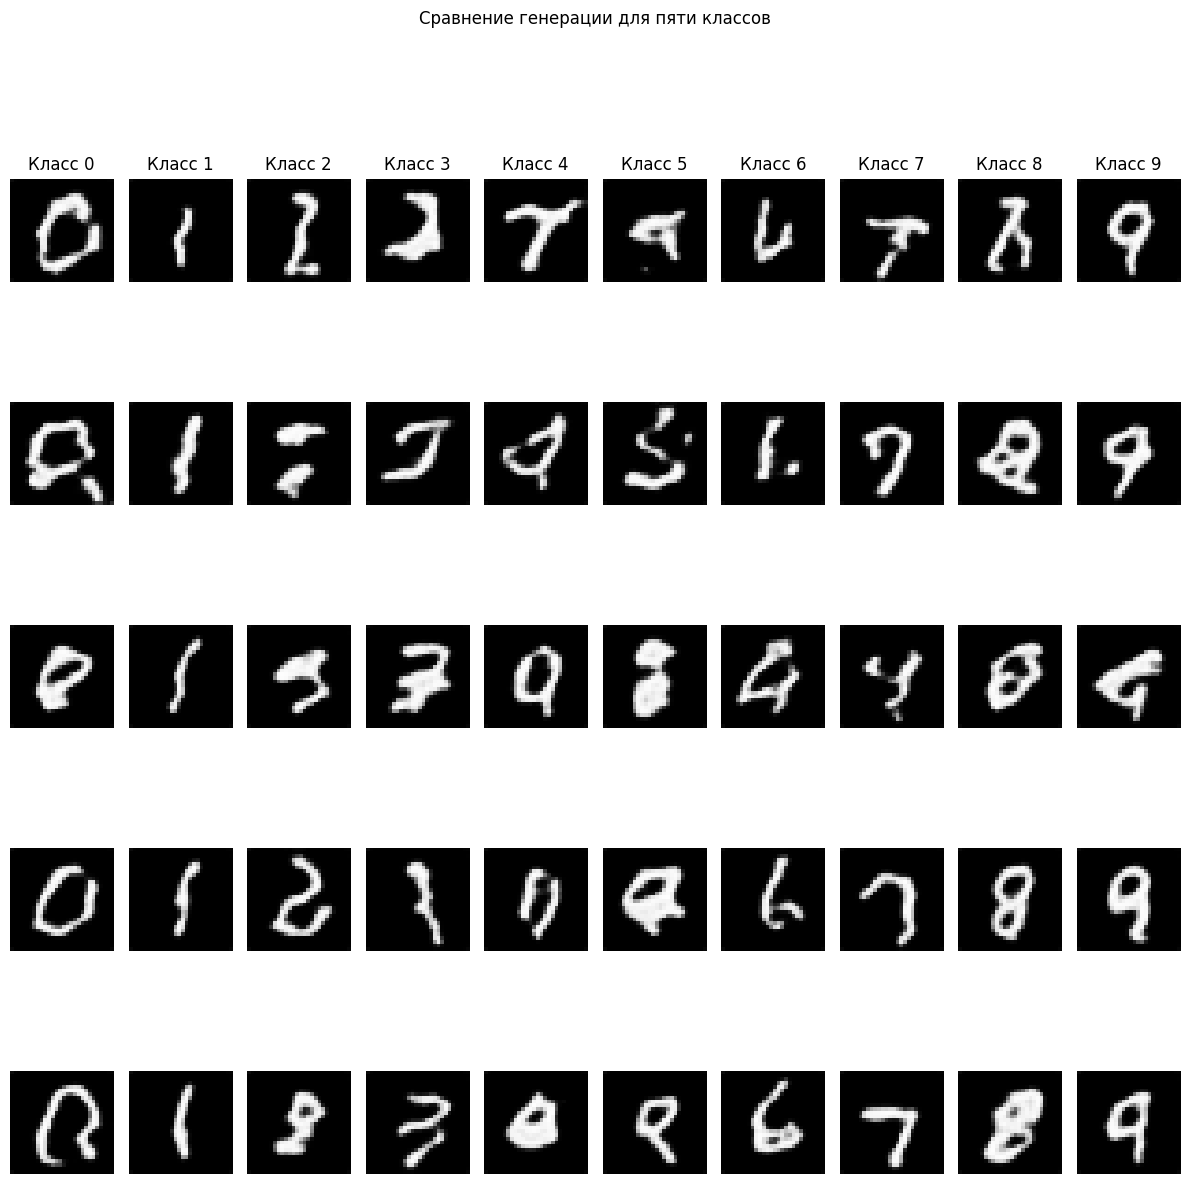

Изображение сохранено: /content/drive/MyDrive/lab16/artifacts/decoded_generation_5_classes.png
Сравнение декодированных изображений завершено.
График: /content/drive/MyDrive/lab16/artifacts/decoded_generation_5_classes.png
Метрики JSON: /content/drive/MyDrive/lab16/artifacts/decoded_generation_metrics.json
Метрики CSV: /content/drive/MyDrive/lab16/artifacts/decoded_generation_metrics.csv
Общий файл изображений: /content/drive/MyDrive/lab16/artifacts/decoded_generation_comparison.pt


In [24]:
# Декодированная генерация и проверка

sampling_file = ARTIFACTS / "generated_tokens_sampling.pt"
tokenizer_file = ARTIFACTS / "vqvae_k64_last.pt"
classifier_file = ARTIFACTS / "class_agreement_last.pt"

for path in [sampling_file, tokenizer_file, classifier_file]:
    assert path.exists(), f"Не найден необходимый файл: {path}"

# Загружаем сгенерированные последовательности
sampling_data = torch.load(sampling_file, map_location="cpu", weights_only=False)
generated_tokens = sampling_data["generated_tokens"]
generation_labels_cpu = sampling_data["generation_labels"]
sampling_configs = sampling_data["sampling_configs"]

# Загружаем VQ-VAE
tokenizer_ckpt = torch.load(tokenizer_file, map_location=DEVICE, weights_only=False)
tokenizer = VQVAE(
    num_embeddings=64,
    latent_dim=tokenizer_ckpt["latent_dim"]
).to(DEVICE)
tokenizer.load_state_dict(tokenizer_ckpt["model"])
tokenizer.eval()

# Загружаем проверяющий классификатор
classifier_ckpt = torch.load(classifier_file, map_location=DEVICE, weights_only=False)
classifier = ClassAgreementCNN().to(DEVICE)
classifier.load_state_dict(classifier_ckpt["model_state_dict"])
classifier.eval()

@torch.no_grad()
def decode_generated_tokens(tokenizer, token_ids):
    """
    Преобразует [B, 49] в изображения [B, 1, 28, 28].
    Используется embedding обученного codebook и decoder VQ-VAE.
    """
    token_ids = token_ids.to(DEVICE).long()

    if hasattr(tokenizer, "decode_indices"):
        images = tokenizer.decode_indices(token_ids)
        return images.clamp(0, 1)

    quantized = tokenizer.quantizer.embedding(token_ids)

    batch_size = token_ids.size(0)
    latent_dim = quantized.size(-1)

    quantized = quantized.view(batch_size, 7, 7, latent_dim)
    quantized = quantized.permute(0, 3, 1, 2).contiguous()

    images = tokenizer.decoder(quantized)
    return images.clamp(0, 1)


@torch.no_grad()
def evaluate_generated_images(images, labels, classifier, batch_size=128):
    """Accuracy, confidence и предсказания классификатора."""
    all_predictions = []
    all_confidences = []

    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size].to(DEVICE)
        logits = classifier(batch)
        probabilities = torch.softmax(logits, dim=1)

        confidence, prediction = probabilities.max(dim=1)
        all_predictions.append(prediction.cpu())
        all_confidences.append(confidence.cpu())

    predictions = torch.cat(all_predictions)
    confidences = torch.cat(all_confidences)

    accuracy = (predictions == labels.cpu()).float().mean().item()

    return {
        "accuracy": accuracy,
        "mean_confidence": confidences.mean().item(),
        "predictions": predictions,
        "confidences": confidences,
    }


def calculate_image_diversity(images):
    """Среднее попарное MSE для сгенерированных изображений."""
    flat = images.flatten(start_dim=1).float()

    if flat.size(0) < 2:
        return 0.0

    # Вычисляем попарное MSE без диагонали
    squared = torch.cdist(flat, flat, p=2).pow(2) / flat.size(1)
    n = squared.size(0)
    return (squared.sum() / (n * (n - 1))).item()


# Декодируем каждую схему и измеряем результаты
decoded_images = {}
decoded_metrics = {}
generation_labels = generation_labels_cpu.long()

for scheme_name in sampling_configs:
    token_ids = generated_tokens[scheme_name].long()

    images = decode_generated_tokens(tokenizer, token_ids)
    assert images.shape == (len(token_ids), 1, 28, 28), (
        f"Неожиданная форма изображений для {scheme_name}: {tuple(images.shape)}"
    )

    decoded_images[scheme_name] = images.cpu()

    classifier_result = evaluate_generated_images(
        images, generation_labels, classifier
    )

    unique_sequences = torch.unique(token_ids, dim=0).size(0)
    unique_codes = torch.unique(token_ids).numel()

    decoded_metrics[scheme_name] = {
        "num_images": int(images.size(0)),
        "unique_token_sequences": int(unique_sequences),
        "unique_code_count": int(unique_codes),
        "code_utilization": float(unique_codes / 64),
        "classifier_accuracy": float(classifier_result["accuracy"]),
        "classifier_mean_confidence": float(classifier_result["mean_confidence"]),
        "mean_pairwise_image_mse": float(calculate_image_diversity(images.cpu())),
        "mean_pixel_value": float(images.mean().item()),
        "pixel_std": float(images.std().item()),
        "images_min": float(images.min().item()),
        "images_max": float(images.max().item()),
    }

    # Сохраняем сами декодированные изображения
    torch.save(
        {
            "images": images.cpu(),
            "labels": generation_labels,
            "predictions": classifier_result["predictions"],
            "confidences": classifier_result["confidences"],
        },
        ARTIFACTS / f"decoded_images_{scheme_name}.pt"
    )

# Сохраняем общий файл с изображениями всех схем
torch.save(
    {
        "decoded_images": decoded_images,
        "labels": generation_labels,
        "metrics": decoded_metrics,
        "sampling_configs": sampling_configs,
    },
    ARTIFACTS / "decoded_generation_comparison.pt"
)

# Таблица измерений
decoded_df = pd.DataFrame([
    {
        "Схема": name,
        "Изображений": m["num_images"],
        "Уникальных последовательностей": m["unique_token_sequences"],
        "Использовано кодов": m["unique_code_count"],
        "Использование codebook": m["code_utilization"],
        "Accuracy классификатора": m["classifier_accuracy"],
        "Средняя уверенность": m["classifier_mean_confidence"],
        "Попарное MSE изображений": m["mean_pairwise_image_mse"],
        "Среднее значение пикселя": m["mean_pixel_value"],
        "Стандартное отклонение пикселей": m["pixel_std"],
    }
    for name, m in decoded_metrics.items()
])

display(
    decoded_df.style.format({
        "Использование codebook": "{:.3f}",
        "Accuracy классификатора": "{:.3f}",
        "Средняя уверенность": "{:.3f}",
        "Попарное MSE изображений": "{:.5f}",
        "Среднее значение пикселя": "{:.3f}",
        "Стандартное отклонение пикселей": "{:.3f}",
    })
)

# Визуальное сравнение: 5 разных классов для каждой схемы

selected_classes = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

scheme_names = list(decoded_images.keys())

fig, axes = plt.subplots(
    len(scheme_names),
    len(selected_classes),
    figsize=(12, 2.5 * len(scheme_names))
)

for row, scheme_name in enumerate(scheme_names):
    images = decoded_images[scheme_name]

    for col, class_id in enumerate(selected_classes):
        # Находим первое изображение нужного класса
        indices = torch.where(generation_labels == class_id)[0]

        if len(indices) == 0:
            raise ValueError(f"Нет сгенерированных изображений класса {class_id}")

        idx = indices[0].item()

        axes[row, col].imshow(
            images[idx, 0].detach().cpu().numpy(),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(f"Класс {class_id}")

    axes[row, 0].set_ylabel(
        scheme_name.replace("_", "\n"),
        rotation=0,
        labelpad=45,
        va="center"
    )

plt.suptitle(
    "Сравнение генерации для пяти классов",
    y=1.02
)

plt.tight_layout()

figure_path = ARTIFACTS / "decoded_generation_5_classes.png"
plt.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

print("Изображение сохранено:", figure_path)

# Сохраняем измерения в JSON и CSV
decoded_metadata = {
    "status": "completed",
    "comparison_type": "decoded_images",
    "num_images_per_scheme": int(len(generation_labels)),
    "tokenizer_checkpoint": str(tokenizer_file),
    "prior_checkpoint": str(ARTIFACTS / "prior_last.pt"),
    "classifier_checkpoint": str(classifier_file),
    "metrics": decoded_metrics,
}

save_json("decoded_generation_metrics.json", decoded_metadata)
decoded_df.to_csv(
    ARTIFACTS / "decoded_generation_metrics.csv",
    index=False
)

print("Сравнение декодированных изображений завершено.")
print("График:", figure_path)
print("Метрики JSON:", ARTIFACTS / "decoded_generation_metrics.json")
print("Метрики CSV:", ARTIFACTS / "decoded_generation_metrics.csv")
print("Общий файл изображений:", ARTIFACTS / "decoded_generation_comparison.pt")

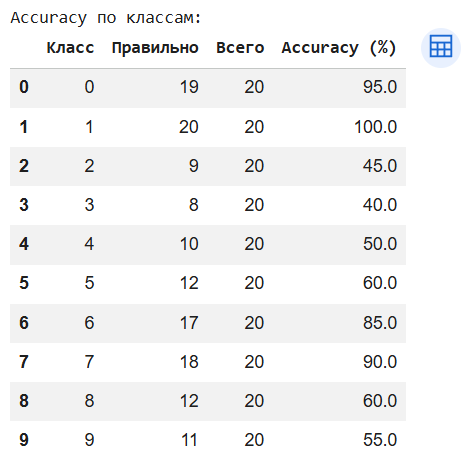

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

**Гипотеза.** Уменьшение температуры семплирования с 1.0 до 0.4 должно снизить случайность авторегрессионной генерации. Ожидается уменьшение разнообразия последовательностей визуальных токенов и попарного расстояния между декодированными изображениями.

control_T1.0: temperature=1.0, unique_sequences=40, image_MSE=0.109284
ablation_T0.4: temperature=0.4, unique_sequences=40, image_MSE=0.089697


,Эксперимент,Temperature,Изображений,Уникальных последовательностей,Доля уникальных последовательностей,Использовано кодов,Использование codebook,Энтропия токенов,Perplexity токенов,Попарное MSE изображений,Среднее пикселей,Станд. отклонение пикселей
0,control_T1.0,1.000000,40,40,1.000,59,0.922,2.761,15.817,0.109284,0.1252,0.2888
1,ablation_T0.4,0.400000,40,40,1.000,57,0.891,2.503,12.223,0.089697,0.1096,0.2773


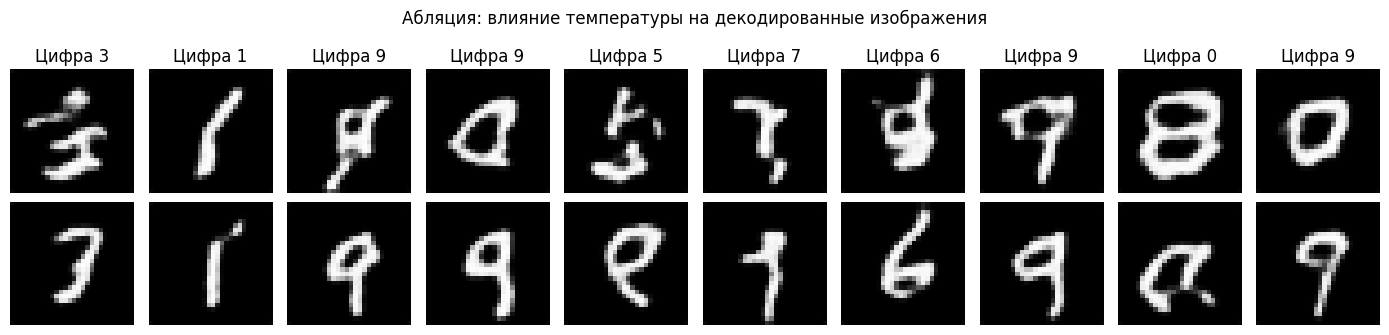


Абляция завершена.
Таблица: /content/drive/MyDrive/lab16/artifacts/temperature_ablation_metrics.csv
JSON: /content/drive/MyDrive/lab16/artifacts/temperature_ablation_metrics.json
Изображения: /content/drive/MyDrive/lab16/artifacts/temperature_ablation.png
Checkpoint результатов: /content/drive/MyDrive/lab16/artifacts/temperature_ablation.pt


In [25]:
# ============================================================
# ТВОРЧЕСКОЕ МИНИ-ИССЛЕДОВАНИЕ: АБЛЯЦИЯ ТЕМПЕРАТУРЫ
# Меняем только temperature: 1.0 -> 0.4
# ============================================================

# ------------------------------------------------------------
# 1. Фиксируем условия эксперимента
# ------------------------------------------------------------

ABLATION_SEED = SEED + 777
ABLATION_N = 40
ABLATION_TEMPERATURES = {
    "control_T1.0": 1.0,
    "ablation_T0.4": 0.4,
}

# Используем реальные метки из MNIST train.
# Один и тот же набор меток будет использоваться в обоих экспериментах.
prepared_path = DATA_ROOT / "mnist_prepared.pt"
prepared = torch.load(prepared_path, map_location="cpu", weights_only=False)
y_train_ablation = prepared["y_train"].long()

index_generator = torch.Generator(device="cpu")
index_generator.manual_seed(ABLATION_SEED)

selected_indices = torch.randperm(
    len(y_train_ablation),
    generator=index_generator
)[:ABLATION_N]

ablation_labels = y_train_ablation[selected_indices].to(DEVICE)

# ------------------------------------------------------------
# 2. Загружаем одну и ту же обученную модель prior
# ------------------------------------------------------------

prior_ckpt = torch.load(
    ARTIFACTS / "prior_last.pt",
    map_location=DEVICE,
    weights_only=False
)

prior_ablation = AutoregressivePrior().to(DEVICE)
prior_ablation.load_state_dict(prior_ckpt["model_state_dict"])
prior_ablation.eval()

# ------------------------------------------------------------
# 3. Функция генерации с заданной температурой
# ------------------------------------------------------------

@torch.no_grad()
def generate_with_temperature(model, labels, temperature, seed):
    model.eval()

    batch_size = labels.size(0)
    seq_len = 49
    bos_token = 64

    generator = torch.Generator(device=DEVICE)
    generator.manual_seed(seed)

    input_ids = torch.full(
        (batch_size, seq_len),
        bos_token,
        dtype=torch.long,
        device=DEVICE
    )

    generated = torch.empty(
        (batch_size, seq_len),
        dtype=torch.long,
        device=DEVICE
    )

    for position in range(seq_len):
        logits = model(input_ids, labels)
        next_logits = logits[:, position, :] / temperature

        probabilities = torch.softmax(next_logits, dim=-1)

        next_token = torch.multinomial(
            probabilities,
            num_samples=1,
            generator=generator
        ).squeeze(1)

        generated[:, position] = next_token

        if position + 1 < seq_len:
            input_ids[:, position + 1] = next_token

    return generated


# ------------------------------------------------------------
# 4. Загружаем один и тот же VQ-VAE-декодер
# ------------------------------------------------------------

vq_ckpt = torch.load(
    ARTIFACTS / "vqvae_k64_last.pt",
    map_location=DEVICE,
    weights_only=False
)

tokenizer_ablation = VQVAE(
    num_embeddings=64,
    latent_dim=vq_ckpt["latent_dim"]
).to(DEVICE)

tokenizer_ablation.load_state_dict(vq_ckpt["model"])
tokenizer_ablation.eval()


@torch.no_grad()
def decode_ablation_tokens(token_ids):
    token_ids = token_ids.to(DEVICE).long()

    quantized = tokenizer_ablation.quantizer.embedding(token_ids)

    batch_size = token_ids.size(0)
    latent_dim = quantized.size(-1)

    quantized = quantized.view(batch_size, 7, 7, latent_dim)
    quantized = quantized.permute(0, 3, 1, 2).contiguous()

    return tokenizer_ablation.decoder(quantized).clamp(0, 1)


# ------------------------------------------------------------
# 5. Метрики разнообразия и декодированных изображений
# ------------------------------------------------------------

def calculate_ablation_metrics(tokens, images):
    tokens = tokens.cpu()
    images = images.detach().cpu()

    unique_sequences = torch.unique(tokens, dim=0).size(0)
    used_codes = torch.unique(tokens).numel()

    counts = torch.bincount(tokens.flatten(), minlength=64).float()
    probabilities = counts / counts.sum()
    nonzero = probabilities[probabilities > 0]

    token_entropy = -(
        nonzero * torch.log(nonzero)
    ).sum().item()

    token_perplexity = float(np.exp(token_entropy))

    flat_images = images.flatten(start_dim=1).float()

    if len(flat_images) > 1:
        pairwise = torch.cdist(flat_images, flat_images, p=2).pow(2)
        pairwise_mse = (
            pairwise.sum() /
            (len(flat_images) * (len(flat_images) - 1) * flat_images.size(1))
        ).item()
    else:
        pairwise_mse = 0.0

    return {
        "num_images": int(images.size(0)),
        "unique_sequences": int(unique_sequences),
        "unique_sequence_fraction": float(unique_sequences / len(tokens)),
        "used_codes": int(used_codes),
        "codebook_utilization": float(used_codes / 64),
        "token_entropy": float(token_entropy),
        "token_perplexity": float(token_perplexity),
        "image_pairwise_mse": float(pairwise_mse),
        "image_pixel_mean": float(images.mean().item()),
        "image_pixel_std": float(images.std().item()),
    }


# ------------------------------------------------------------
# 6. Проводим два эксперимента
# ------------------------------------------------------------

ablation_tokens = {}
ablation_images = {}
ablation_metrics = {}

start_time = time.time()

for name, temperature in ABLATION_TEMPERATURES.items():

    # ВАЖНО: одинаковый seed и одинаковые метки для обеих настроек.
    tokens = generate_with_temperature(
        prior_ablation,
        ablation_labels,
        temperature=temperature,
        seed=ABLATION_SEED
    )

    images = decode_ablation_tokens(tokens)

    ablation_tokens[name] = tokens.cpu()
    ablation_images[name] = images.cpu()

    metrics = calculate_ablation_metrics(tokens, images)
    metrics["temperature"] = temperature
    ablation_metrics[name] = metrics

    print(
        f"{name}: temperature={temperature}, "
        f"unique_sequences={metrics['unique_sequences']}, "
        f"image_MSE={metrics['image_pairwise_mse']:.6f}"
    )

ablation_time = time.time() - start_time


# ------------------------------------------------------------
# 7. Таблица результатов
# ------------------------------------------------------------

ablation_df = pd.DataFrame([
    {
        "Эксперимент": name,
        "Temperature": m["temperature"],
        "Изображений": m["num_images"],
        "Уникальных последовательностей": m["unique_sequences"],
        "Доля уникальных последовательностей": m["unique_sequence_fraction"],
        "Использовано кодов": m["used_codes"],
        "Использование codebook": m["codebook_utilization"],
        "Энтропия токенов": m["token_entropy"],
        "Perplexity токенов": m["token_perplexity"],
        "Попарное MSE изображений": m["image_pairwise_mse"],
        "Среднее пикселей": m["image_pixel_mean"],
        "Станд. отклонение пикселей": m["image_pixel_std"],
    }
    for name, m in ablation_metrics.items()
])

display(
    ablation_df.style.format({
        "Доля уникальных последовательностей": "{:.3f}",
        "Использование codebook": "{:.3f}",
        "Энтропия токенов": "{:.3f}",
        "Perplexity токенов": "{:.3f}",
        "Попарное MSE изображений": "{:.6f}",
        "Среднее пикселей": "{:.4f}",
        "Станд. отклонение пикселей": "{:.4f}",
    })
)


# ------------------------------------------------------------
# 8. Визуальное сравнение одинаковых классов
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 10, figsize=(14, 3.5))

for row, name in enumerate(ABLATION_TEMPERATURES):
    images = ablation_images[name]

    for col in range(10):
        axes[row, col].imshow(
            images[col, 0].detach().cpu().numpy(),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(
                f"Цифра {ablation_labels[col].item()}"
            )

    axes[row, 0].set_ylabel(
        f"T={ABLATION_TEMPERATURES[name]}",
        rotation=0,
        labelpad=35,
        va="center"
    )

plt.suptitle("Абляция: влияние температуры на декодированные изображения")
plt.tight_layout()

ablation_figure_path = ARTIFACTS / "temperature_ablation.png"
plt.savefig(ablation_figure_path, dpi=160, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# 9. Сохраняем артефакты
# ------------------------------------------------------------

torch.save(
    {
        "tokens": ablation_tokens,
        "images": ablation_images,
        "labels": ablation_labels.cpu(),
        "temperatures": ABLATION_TEMPERATURES,
        "seed": ABLATION_SEED,
    },
    ARTIFACTS / "temperature_ablation.pt"
)

ablation_report = {
    "status": "completed",
    "hypothesis": (
        "Снижение temperature с 1.0 до 0.4 уменьшит разнообразие "
        "генерируемых последовательностей и декодированных изображений."
    ),
    "changed_factor": "sampling_temperature",
    "control_temperature": 1.0,
    "ablation_temperature": 0.4,
    "same_prior_checkpoint": str(ARTIFACTS / "prior_last.pt"),
    "same_tokenizer_checkpoint": str(ARTIFACTS / "vqvae_k64_last.pt"),
    "same_real_training_labels": True,
    "same_seed": ABLATION_SEED,
    "num_images_per_setting": ABLATION_N,
    "test_used_for_selection": False,
    "elapsed_seconds": ablation_time,
    "metrics": ablation_metrics,
}

save_json("temperature_ablation_metrics.json", ablation_report)
ablation_df.to_csv(
    ARTIFACTS / "temperature_ablation_metrics.csv",
    index=False
)

print("\nАбляция завершена.")
print("Таблица:", ARTIFACTS / "temperature_ablation_metrics.csv")
print("JSON:", ARTIFACTS / "temperature_ablation_metrics.json")
print("Изображения:", ablation_figure_path)
print("Checkpoint результатов:", ARTIFACTS / "temperature_ablation.pt")

## Анализ результатов

В ходе работы были обучены два визуальных токенизатора с размером словаря 16 и 64. Оба обучались по 1000 шагов на одинаковых данных. **Модель с 64 кодами показала лучший результат: разнообразие и Perplexity выше.** При этом обе модели использовали все доступные коды.

Авторегрессионная модель показала ошибку 1.244 на обучающей выборке и 1.171 на тестовой. **Разница небольшая, поэтому явных признаков переобучения не наблюдается.** Точность классификатора на тестовой выборке составила **98.30%**, что говорит о его хорошей способности распознавать цифры.

При сравнении схем генерации все варианты создали по 200 уникальных последовательностей. Лучший результат показала комбинация `top_k_top_p`. У неё **accuracy = 0.675**. Увереность классификатора при этом 0.877.

В дополнительном эксперименте я сравнил температуру 1.0 и 0.4. При снижении температуры **энтропия токенов уменьшилась с 2.761 до 2.503, а попарное MSE — с 0.1093 до 0.0897**. Это подтверждает гипотезу: при низкой температуре изображения становятся более похожими друг на друга.

Неудачные примеры и возможные причины:

При просмотре генерации можно я выделил несколько типов ошибок:

1. Неправильная форма цифры — неудачный выбор токенов.
2. Лишние элементы на изображении — ошибки при предсказании отдельных токенов.

**Такие ошибки чаще всего встречались для классов 2, 3 и 4.**

Ограничения: попарное MSE считается по всем классам сразу, поэтому учитывает не только разнообразие внутри класса, но и различия между цифрами. Также высокая уверенность классификатора не всегда означает хорошее качество изображения.

**Вывод: увеличение словаря до 64 кодов улучшило восстановление изображений. Среди схем генерации лучший результат по нескольким метрикам показала комбинация `top_k_top_p`. Снижение температуры уменьшило разнообразие изображений, что подтвердило первоначальную гипотезу.**

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.